**Instituto Tecnológico de Costa Rica**

**Métodos numéricos** - MA3106

**Laboratorio 1:**
Simulación bidimensional de un brazo robótico plano de tres articulaciones


**Estudiantes:**

Ariana Carrillo García - 2023048173 (Coordinadora)

Nasdia Gutiérrez Sacasa - 2023800122

Alison Valeria Quillaos Mairena - 2025127873

Marisol Chacón Rodríguez - 2025069338

**Profesor:** Jeffrey Chavarría Molina

**II semestre 2026**


# **Objetivo del proyecto**

Desarrollar una simulación bidimensional de la cinemática de un brazo robótico plano de tres articulaciones, resolviendo el problema de cinemática inversa para distintas configuraciones. Esto se logrará mediante el planteamiento de sistemas de ecuaciones no lineales y su solución iterativa empleando el método numérico de Newton-Raphson, con el fin de analizar el alcance, la continuidad geométrica y las singularidades del sistema.

#**Declaración de uso de Inteligencia Artificial**

En cumplimiento con las instrucciones establecidas para la entrega de este proyecto, el equipo de trabajo declara que se emplearon herramientas de Inteligencia Artificial (IA) como recurso de apoyo durante el desarrollo del mismo, detallándose su uso de la siguiente manera:

* **Fase de desarrollo y consulta:** Durante la ejecución del laboratorio, distintos miembros del equipo utilizaron de forma individual los modelos de lenguaje Gemini y ChatGPT como asistencia para la resolución de dudas, comprensión de conceptos y apoyo en la estructuración de la información.
* **Fase de revisión final:** Una vez consolidado el proyecto, se empleó ChatGPT para realizar una revisión integral de todo el trabajo final. Esta herramienta se utilizó con el objetivo de verificar la coherencia, afinar la redacción y realizar correcciones de estilo en el documento entregado.

El equipo certifica que las herramientas de Inteligencia Artificial fueron utilizadas estrictamente como un recurso de asistencia complementario. Todos los análisis, implementaciones de código, resultados y conclusiones aquí presentadas han sido rigurosamente evaluados y validados por los miembros del grupo, quienes asumimos la total responsabilidad intelectual, técnica y académica del presente trabajo.

# **Bitácora de reuniones y distribución del trabajo**

| Fecha | Asistentes | Acuerdos y tareas | Responsable | Meta / evidencia |
| :--- | :--- | :--- | :--- | :--- |
| **25/09/2026** | Ariana, Marisol, Alison, Nasdia | Distribución inicial del proyecto. Asignación de roles: Ariana (Modelo matemático y coordinación), Marisol (Newton-Raphson y Fase II), Alison (Programa robusto, Fase I y animaciones), Nasdia (Mapas del espacio de trabajo, Fase III). | Ariana, Marisol, Alison, Nasdia | **Meta:** Distribuir responsabilidades y comenzar el modelo matemático.<br>**Evidencia:** Organización inicial del cuaderno de Google Colab. |
| **28/09/2026** | Ariana, Marisol, Alison, Nasdia | Revisión de avance del modelo matemático. Continuación de la definición de los sistemas no lineales para verificar la base del proyecto. | Ariana | **Meta:** Completar la definición de los sistemas para el método de Newton-Raphson.<br>**Evidencia:** Sistemas matemáticos incorporados y documentados en el cuaderno. |
| **02/10/2026** | Ariana, Marisol, Alison, Nasdia | Revisión de avances de programación. Finalización de la implementación de Newton-Raphson, programa robusto, fases I, II, III y generación de animaciones. | Marisol, Alison, Nasdia | **Meta:** Completar las principales etapas de programación para iniciar la integración.<br>**Evidencia:** Código, resultados, gráficas, animaciones y mapas generados en Google Colab. |
| **07/10/2026** | Ariana, Marisol, Alison, Nasdia | Continuación de la integración general del proyecto. Explicación y documentación detallada del código utilizado para generar los mapas del espacio de trabajo. | Nasdia | **Meta:** Completar la explicación de la Fase III para la comprensión de todo el equipo.<br>**Evidencia:** Explicación incorporada en Google Colab junto con el código y los mapas. |
| **08/10/2026** | Ariana, Marisol, Alison, Nasdia | Revisión y finalización de los apartados administrativos y de documentación general del proyecto (bitácora y uso de IA). | Ariana (revisión del equipo) | **Meta:** Dejar finalizados los apartados de documentación requeridos para la entrega.<br>**Evidencia:** Bitácora y declaración de uso de IA incorporadas en Google Colab. |
| **Reunión final programada:**
**09/10/2026** | Ariana, Marisol, Alison, Nasdia | Revisión completa del cuaderno, verificación de integración, funcionamiento del código, análisis de resultados y repaso general para defensa oral. | Ariana, Marisol, Alison, Nasdia | **Meta:** Revisión integral y asegurar que todas comprendan a profundidad el proyecto globalmente.<br>**Evidencia:** Revisión completa del cuaderno, verificación de código y preparación del equipo. |

#Evidencia de reunión del equipo
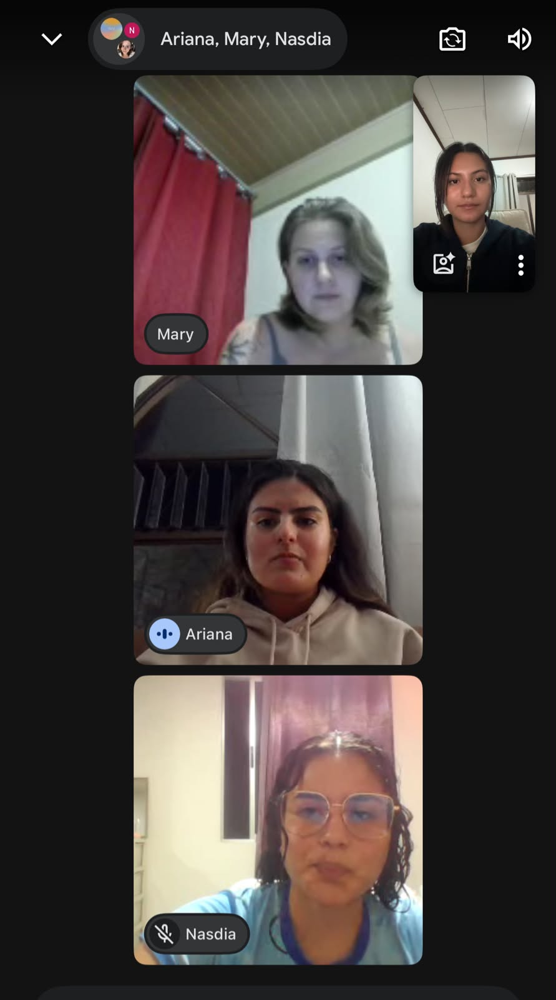

#**Explicación del modelo geométrico del brazo robótico**

El brazo robótico está formado por tres eslabones de longitudes ($l_1$), ($l_2$) y ($l_3$), unidos por tres articulaciones rotacionales. Cada articulación tiene un ángulo asociado, representado por $\theta_1$, $\theta_2$ y $\theta_3$. El movimiento ocurre en el plano \(xy\) y el punto final del brazo corresponde al efector final $P(x,y)$.

La posición del efector se obtiene sumando las componentes horizontales y verticales de los tres eslabones. Por eso, las ecuaciones de posición son:

$$x = l_1\cos(\theta_1) + l_2\cos(\theta_1+\theta_2) + l_3\cos(\theta_1+\theta_2+\theta_3)$$

$$y = l_1\sin(\theta_1) + l_2\sin(\theta_1+\theta_2) + l_3\sin(\theta_1+\theta_2+\theta_3)$$

En este problema, las longitudes de los eslabones y las coordenadas del punto objetivo son datos conocidos, mientras que los ángulos articulares son las incógnitas. Como solo existen dos ecuaciones de posición para tres ángulos, es necesario agregar una tercera ecuación auxiliar para poder determinar una configuración del brazo.

La posición inicial del brazo se define con los tres ángulos iguales a cero, por lo que los eslabones quedan alineados sobre el eje $x$ y el efector se ubica en $(l_1+l_2+l_3,0)$. Desde esta posición se inicia el recorrido hacia los diferentes puntos y al final el brazo regresa nuevamente a su configuración inicial.

# **Planteamiento matemático de los cinco sistemas no lineales**

## Variables conocidas e incógnitas

Para cada punto objetivo, los datos conocidos son las longitudes de los eslabones $l_1, l_2, l_3$ y las coordenadas del efector final $x, y$. Las incógnitas del problema son los tres ángulos articulares: $\theta_1, \theta_2, \theta_3$.

## Ecuaciones de posición y Sistemas $F(\theta)$

La posición del efector final en el plano está dada por dos ecuaciones base que aplican para todos los casos:
* $F_1(\theta_1, \theta_2, \theta_3) = l_1\cos(\theta_1) + l_2\cos(\theta_1+\theta_2) + l_3\cos(\theta_1+\theta_2+\theta_3) - x = 0$
* $F_2(\theta_1, \theta_2, \theta_3) = l_1\sin(\theta_1) + l_2\sin(\theta_1+\theta_2) + l_3\sin(\theta_1+\theta_2+\theta_3) - y = 0$

Estas dos ecuaciones de posición dejan un grado de libertad en el sistema. Para cerrar los grados de libertad, se añade una tercera ecuación $F_3^{(s)}$ dependiendo de la opción seleccionada. Cada ecuación $F_3$ elimina este grado de libertad seleccionando determinadas configuraciones, lo cual permite modificar el alcance, la continuidad y las posibles singularidades del movimiento, formando así un sistema no lineal $F(\theta) = 0$:

* **Opción A (Orientación horizontal):** $F_3^{(A)} = \theta_1 + \theta_2 + \theta_3 = 0$. El ángulo absoluto del tercer eslabón respecto al eje x es cero.
* **Opción B (Orientación vertical):** $F_3^{(B)} = \theta_1 + \theta_2 + \theta_3 - \frac{\pi}{2} = 0$. El tercer eslabón mantiene una orientación vertical positiva.
* **Opción C (Tercer eslabón alineado):** $F_3^{(C)} = \theta_3 = 0$. No hay rotación en la tercera articulación, por lo que el eslabón 3 actúa como una extensión rígida del eslabón 2.
* **Opción D (Ángulos relativos iguales):** $F_3^{(D)} = \theta_2 - \theta_3 = 0$. La rotación del segundo y tercer eslabón es idéntica respecto a su articulación previa.
* **Opción E (Orientación tangencial):** $F_3^{(E)} = \theta_1 + \theta_2 + \theta_3 - \alpha(x,y) - \frac{\pi}{2} = 0$. El último eslabón es perpendicular al segmento que une el origen con el punto $(x,y)$. Para el manejo computacional del ángulo polar $\alpha(x,y) = \text{atan2}(y,x)$, se adopta la convención $\alpha(0,0)=0$. Dado que la función `atan2` devuelve el ángulo principal, es necesario manejar el corte angular y un posible desenvolvimiento (unwrapping) de los ángulos para mantener la continuidad visual en la trayectoria; esto se logra seleccionando representaciones equivalentes próximas a la configuración anterior.

## Construcción de los cinco jacobianos

La matriz jacobiana $J(\theta)$ está formada por las derivadas parciales de cada función respecto a cada ángulo. Las dos primeras filas de la matriz son idénticas para los 5 sistemas:

$$J = \begin{pmatrix} \frac{\partial F_1}{\partial \theta_1} & \frac{\partial F_1}{\partial \theta_2} & \frac{\partial F_1}{\partial \theta_3} \\ \frac{\partial F_2}{\partial \theta_1} & \frac{\partial F_2}{\partial \theta_2} & \frac{\partial F_2}{\partial \theta_3} \\ \frac{\partial F_3}{\partial \theta_1} & \frac{\partial F_3}{\partial \theta_2} & \frac{\partial F_3}{\partial \theta_3} \end{pmatrix}$$

Aplicando la regla de la cadena a $F_1$ y $F_2$, obtenemos las derivadas para las filas 1 y 2:
* $J_{1,1} = -l_1\sin(\theta_1) - l_2\sin(\theta_1+\theta_2) - l_3\sin(\theta_1+\theta_2+\theta_3)$
* $J_{1,2} = -l_2\sin(\theta_1+\theta_2) - l_3\sin(\theta_1+\theta_2+\theta_3)$
* $J_{1,3} = -l_3\sin(\theta_1+\theta_2+\theta_3)$
* $J_{2,1} = l_1\cos(\theta_1) + l_2\cos(\theta_1+\theta_2) + l_3\cos(\theta_1+\theta_2+\theta_3)$
* $J_{2,2} = l_2\cos(\theta_1+\theta_2) + l_3\cos(\theta_1+\theta_2+\theta_3)$
* $J_{2,3} = l_3\cos(\theta_1+\theta_2+\theta_3)$

La tercera fila cambia según la opción elegida:
* **Opción A y B:** $\nabla F_3 = [1, \quad 1, \quad 1]$
* **Opción C:** $\nabla F_3 = [0, \quad 0, \quad 1]$
* **Opción D:** $\nabla F_3 = [0, \quad 1, \quad -1]$
* **Opción E:** $\nabla F_3 = [1, \quad 1, \quad 1]$ (Ya que $\alpha(x,y)$ y $\frac{\pi}{2}$ son constantes respecto a $\theta$).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image

import contextlib
import io

In [ ]:
import numpy as np

def construir_sistema_jacobiano(theta, l1, l2, l3, x, y, opcion):
    """
    Construye el sistema no lineal F(theta) y su matriz Jacobiana J(theta)
    para el método de Newton-Raphson de un brazo de 3 articulaciones.
    """
    t1, t2, t3 = theta

    # 1. Ángulos acumulados
    suma1 = t1
    suma2 = t1 + t2
    suma3 = t1 + t2 + t3

    # 2. Evaluación de las funciones de posición F1 y F2
    F1 = l1*np.cos(suma1) + l2*np.cos(suma2) + l3*np.cos(suma3) - x
    F2 = l1*np.sin(suma1) + l2*np.sin(suma2) + l3*np.sin(suma3) - y

    # 3. Construcción de la matriz Jacobiana (Filas 1 y 2)
    J = np.zeros((3, 3))

    # Derivadas de F1 (Fila 1)
    J[0, 0] = -l1*np.sin(suma1) - l2*np.sin(suma2) - l3*np.sin(suma3)
    J[0, 1] = -l2*np.sin(suma2) - l3*np.sin(suma3)
    J[0, 2] = -l3*np.sin(suma3)

    # Derivadas de F2 (Fila 2)
    J[1, 0] = l1*np.cos(suma1) + l2*np.cos(suma2) + l3*np.cos(suma3)
    J[1, 1] = l2*np.cos(suma2) + l3*np.cos(suma3)
    J[1, 2] = l3*np.cos(suma3)

    # 4. Evaluación de la ecuación auxiliar F3 y la Fila 3 del Jacobiano
    F3 = 0.0

    if opcion == 'A':
        F3 = suma3
        J[2, :] = [1, 1, 1]

    elif opcion == 'B':
        F3 = suma3 - (np.pi / 2)
        J[2, :] = [1, 1, 1]

    elif opcion == 'C':
        F3 = t3
        J[2, :] = [0, 0, 1]

    elif opcion == 'D':
        F3 = t2 - t3
        J[2, :] = [0, 1, -1]

    elif opcion == 'E':
        # Convención especial para el origen
        if x == 0 and y == 0:
            alpha = 0
        else:
            alpha = np.arctan2(y, x)

        F3 = suma3 - alpha - (np.pi / 2)
        J[2, :] = [1, 1, 1]

    else:
        raise ValueError("Opción no válida. Ingrese A, B, C, D o E.")

    # Agrupar las funciones evaluadas en un vector columna
    F = np.array([F1, F2, F3])

    return F, J

#**Newton-Raphson para un punto y análisis de compatibilidad**
##Se implementa la función NR_Un_Punto

### Aplicación de Newton-Raphson

Se parte de una suposición inicial de los tres ángulos. En cada iteración se evalúan el sistema F y su matriz jacobiana J, y se calcula la corrección resolviendo:

$$
J(\theta^{(k)})\Delta\theta^{(k)}=-F(\theta^{(k)})
$$

Después se actualizan los ángulos:

$$
\theta^{(k+1)}=\theta^{(k)}+\Delta\theta^{(k)}
$$

La suposición inicial predeterminada es (0.5, 0.5, -1.0), en radianes. No se utiliza (0, 0, 0) como inicio general porque, con el brazo completamente extendido, el jacobiano es singular para las opciones del laboratorio.

El método termina cuando la norma 2 del residuo es menor o igual que 10⁻⁶. Si el jacobiano es singular o se completan 100 iteraciones sin cumplir la tolerancia, se informa un fallo numérico.

####Verificación del alcance geométrico del brazo

In [ ]:
def crear_resultado_NR(x, y, opcion, radianes, iteraciones,
                       residuo, convergio, mensaje):
    return {
        "Punto": (x, y),
        "Opción": opcion,
        "Ángulos (rad)": radianes,
        "Ángulos (°)": (
            np.degrees(radianes) if radianes is not None else None
        ),
        "Iteraciones": iteraciones,
        "Residuo": residuo,
        "Convergió": convergio,
        "Mensaje": mensaje}

In [ ]:
def verificar_alcance(l1, l2, l3, x, y):
    # Distancia desde el origen hasta el punto objetivo
    distancia = np.hypot(x, y)

    # Distancias máxima y mínima que puede alcanzar el brazo
    alcance_maximo = l1 + l2 + l3
    alcance_minimo = max(0.0, 2 * max(l1, l2, l3) - alcance_maximo)

    return alcance_minimo <= distancia <= alcance_maximo

def verificar_compatibilidad_A(l1, l2, l3, x, y):
    # En A, el último segmento apunta hacia la derecha
    x_union = x - l3
    y_union = y

    # Comprobar si los primeros dos segmentos alcanzan la unión
    distancia_union = np.hypot(x_union, y_union)
    minimo = abs(l1 - l2)
    maximo = l1 + l2

    return minimo <= distancia_union <= maximo

In [ ]:
def NR_Un_Punto(l1, l2, l3, x, y, opcion,
                theta_inicial=(0.5, 0.5, -1.0),
                tolerancia=1e-6, max_iter=100):

    # Comprobar el alcance geométrico
    if not verificar_alcance(l1, l2, l3, x, y):
        return crear_resultado_NR(
            x, y, opcion, None, 0, np.inf, False,
            "Fuera del alcance geométrico")

    # Comprobar la compatibilidad con la opción A
    if opcion == "A":
        if not verificar_compatibilidad_A(l1, l2, l3, x, y):
            return crear_resultado_NR(
                x, y, opcion, None, 0, np.inf, False,
                "Punto incompatible con la opción A")

    # Comprobar la compatibilidad con la opción B
    if opcion == "B":
        if not verificar_compatibilidad_B(l1, l2, l3, x, y):
            return crear_resultado_NR(
                x, y, opcion, None, 0, np.inf, False,
                "Punto incompatible con la opción B")

    # Comprobar la compatibilidad con la opción C
    if opcion == "C":
        if not verificar_compatibilidad_C(l1, l2, l3, x, y):
            return crear_resultado_NR(
                x, y, opcion, None, 0, np.inf, False,"Punto incompatible con la opción C")

    # Comprobar la compatibilidad con la opción E
    if opcion == "E":
        if not verificar_compatibilidad_E(l1, l2, l3, x, y):
            return crear_resultado_NR(
                x, y, opcion, None, 0, np.inf, False,
                "Punto incompatible con la opción E")

    # Preparar una copia de los ángulos iniciales
    theta = np.array(theta_inicial, dtype=float, copy=True)

    # Evaluar el sistema y su jacobiano
    F, J = construir_sistema_jacobiano(theta, l1, l2, l3, x, y, opcion)

    # Medir el error conjunto mediante la norma 2
    residuo = np.linalg.norm(F, ord=2)

    # Comprobar si los ángulos iniciales ya son una solución
    if residuo <= tolerancia:
        return crear_resultado_NR(
            x, y, opcion, theta, 0, residuo, True,
            "Convergió con la suposición inicial")

    # Realizar las correcciones de Newton-Raphson
    for iteracion in range(1, max_iter + 1):

        # Resolver J · delta = -F
        try:
            delta = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            return crear_resultado_NR(
                x, y, opcion, theta, iteracion - 1,
                residuo, False,
                "Fallo numérico: el jacobiano es singular")

        # Actualizar los ángulos
        theta = theta + delta

        # Evaluar nuevamente el sistema y su jacobiano
        F, J = construir_sistema_jacobiano(
            theta, l1, l2, l3, x, y, opcion)
        residuo = np.linalg.norm(F, ord=2)

        # Terminar si el residuo cumple la tolerancia
        if residuo <= tolerancia:
            return crear_resultado_NR(
                x, y, opcion, theta, iteracion,
                residuo, True,
                "Convergió: el residuo cumple la tolerancia" )

    # Terminar si se agotaron las iteraciones
    return crear_resultado_NR(
        x, y, opcion, theta, max_iter, residuo, False,
        "Fallo numérico: se alcanzó el máximo de iteraciones")

In [ ]:
def verificar_compatibilidad_A(l1, l2, l3, x, y):
    # Punto al que deben llegar los primeros dos segmentos
    x_union = x - l3
    y_union = y

    # Distancia desde el origen hasta esa unión
    distancia_union = np.hypot(x_union, y_union)

    # Alcance de los primeros dos segmentos
    minimo = abs(l1 - l2)
    maximo = l1 + l2

    return minimo <= distancia_union <= maximo

In [ ]:
def verificar_compatibilidad_B(l1, l2, l3, x, y):
    # Punto al que deben llegar los primeros dos segmentos
    x_union = x
    y_union = y - l3

    # Distancia desde el origen hasta esa unión
    distancia_union = np.hypot(x_union, y_union)

    # Alcance de los primeros dos segmentos
    minimo = abs(l1 - l2)
    maximo = l1 + l2

    return minimo <= distancia_union <= maximo

In [ ]:
def verificar_compatibilidad_C(l1, l2, l3, x, y):
    # Distancia desde el origen hasta el punto
    distancia = np.hypot(x, y)

    # El segundo y tercer segmento actúan como uno solo
    longitud_combinada = l2 + l3

    minimo = abs(l1 - longitud_combinada)
    maximo = l1 + longitud_combinada

    return minimo <= distancia <= maximo

In [ ]:
def verificar_compatibilidad_E(l1, l2, l3, x, y):
    # Calcular la dirección del punto objetivo
    if x == 0 and y == 0:
        alpha = 0
    else:
        alpha = np.arctan2(y, x)

    # Orientación exigida para el último segmento
    orientacion = alpha + np.pi / 2

    # Posición que deben alcanzar los primeros dos segmentos
    x_union = x - l3 * np.cos(orientacion)
    y_union = y - l3 * np.sin(orientacion)

    distancia_union = np.hypot(x_union, y_union)

    # Alcance de los primeros dos segmentos
    minimo = abs(l1 - l2)
    maximo = l1 + l2

    return minimo <= distancia_union <= maximo

In [ ]:
# Resolver un punto de prueba
resultado = NR_Un_Punto(
    l1=1.0, l2=1.0, l3=1.0,
    x=2.0, y=1.0,
    opcion="A",
    theta_inicial=[0.5, 0.5, -1.0]
)

# Mostrar la salida completa
print("Punto objetivo:", resultado["Punto"])
print("Opción utilizada:", resultado["Opción"])
print("¿Convergió?:", resultado["Convergió"])
print("Ángulos en radianes:", resultado["Ángulos (rad)"])
print("Ángulos en grados:", resultado["Ángulos (°)"])
print("Correcciones realizadas:", resultado["Iteraciones"])
print("Residuo final:", resultado["Residuo"])
print("Mensaje:", resultado["Mensaje"])

Punto objetivo: (2.0, 1.0)
Opción utilizada: A
¿Convergió?: True
Ángulos en radianes: [-8.07251015e-12  1.57079633e+00 -1.57079633e+00]
Ángulos en grados: [-4.62520762e-10  9.00000000e+01 -9.00000000e+01]
Correcciones realizadas: 5
Residuo final: 8.072569617653679e-12
Mensaje: Convergió: el residuo cumple la tolerancia


In [ ]:
resultado = NR_Un_Punto(1, 1, 1, 4, 0, "A")
print(resultado)

{'Punto': (4, 0), 'Opción': 'A', 'Ángulos (rad)': None, 'Ángulos (°)': None, 'Iteraciones': 0, 'Residuo': inf, 'Convergió': False, 'Mensaje': 'Fuera del alcance geométrico'}


## Verificación de compatibilidad con la opción A

In [ ]:
resultado = NR_Un_Punto(1, 1, 1, -1.4, 0.3, "A")
print(resultado)

{'Punto': (-1.4, 0.3), 'Opción': 'A', 'Ángulos (rad)': None, 'Ángulos (°)': None, 'Iteraciones': 0, 'Residuo': inf, 'Convergió': False, 'Mensaje': 'Punto incompatible con la opción A'}


## Verificación de compatibilidad con la opción B

In [ ]:
resultado = NR_Un_Punto(1, 1, 1, 0.3, -1.4, "B")
print(resultado)

{'Punto': (0.3, -1.4), 'Opción': 'B', 'Ángulos (rad)': None, 'Ángulos (°)': None, 'Iteraciones': 0, 'Residuo': inf, 'Convergió': False, 'Mensaje': 'Punto incompatible con la opción B'}


## Verificación de compatibilidad con la opción C

In [ ]:
resultado = NR_Un_Punto(1, 1, 1, 0.5, 0.5, "C")
print(resultado)

{'Punto': (0.5, 0.5), 'Opción': 'C', 'Ángulos (rad)': None, 'Ángulos (°)': None, 'Iteraciones': 0, 'Residuo': inf, 'Convergió': False, 'Mensaje': 'Punto incompatible con la opción C'}


## Compatibilidad con la opción D

La opción D exige que θ₂ = θ₃. Para l₁ = l₂ = l₃ = 1,
la distancia del efector al origen es r = |1 + 2 cos(θ₂)|,
que puede tomar cualquier valor entre 0 y 3. El ángulo θ₁
permite orientar la configuración en cualquier dirección.

Por tanto, D conserva todo el alcance geométrico del brazo
para estas longitudes. La falta de convergencia de Newton-Raphson
no demuestra incompatibilidad.

## Compatibilidad con la opción E

In [ ]:
resultado = NR_Un_Punto(1, 1, 1, 1.3, 1.3, "E")
print(resultado)

{'Punto': (1.3, 1.3), 'Opción': 'E', 'Ángulos (rad)': None, 'Ángulos (°)': None, 'Iteraciones': 0, 'Residuo': inf, 'Convergió': False, 'Mensaje': 'Punto incompatible con la opción E'}


## Validación de Newton-Raphson con distintas suposiciones iniciales

In [ ]:
# Resolver el mismo punto con dos suposiciones iniciales
suposiciones = [
    (0.5, 0.5, -1.0),
    (1.0, -0.5, -0.5)
]

for inicial in suposiciones:
    resultado = NR_Un_Punto(
        1, 1, 1, 1.5, 0.5, "A",
        theta_inicial=inicial
    )

    print("Ángulos iniciales:", inicial)
    print("Punto objetivo:", resultado["Punto"])
    print("Opción utilizada:", resultado["Opción"])
    print("¿Convergió?:", resultado["Convergió"])
    print("Ángulos en radianes:", resultado["Ángulos (rad)"])
    print("Ángulos en grados:", resultado["Ángulos (°)"])
    print("Correcciones realizadas:", resultado["Iteraciones"])
    print("Residuo final:", resultado["Residuo"])
    print("Mensaje:", resultado["Mensaje"])
    print()

Ángulos iniciales: (0.5, 0.5, -1.0)
Punto objetivo: (1.5, 0.5)
Opción utilizada: A
¿Convergió?: True
Ángulos en radianes: [ 1.99482737 -2.41885841  0.42403104]
Ángulos en grados: [ 114.29518895 -138.59037789   24.29518895]
Correcciones realizadas: 8
Residuo final: 6.604283264905962e-12
Mensaje: Convergió: el residuo cumple la tolerancia

Ángulos iniciales: (1.0, -0.5, -0.5)
Punto objetivo: (1.5, 0.5)
Opción utilizada: A
¿Convergió?: True
Ángulos en radianes: [-0.42403104  2.41885841 -1.99482737]
Ángulos en grados: [ -24.29518895  138.59037789 -114.29518895]
Correcciones realizadas: 8
Residuo final: 6.603722993136271e-12
Mensaje: Convergió: el residuo cumple la tolerancia



Las dos suposiciones iniciales convergieron en 8 correcciones,
con residuos aproximados de 6.60 × 10⁻¹², inferiores a la
tolerancia de 10⁻⁶. Se obtuvieron dos configuraciones distintas
que alcanzan el punto (1.5, 0.5) y cumplen la condición A.
Esto muestra que la suposición inicial puede influir en la
configuración encontrada por Newton-Raphson.

In [ ]:
resultado = NR_Un_Punto(
    1, 1, 1, 1.5, 0.5, "A",
    theta_inicial=(0, 0, 0))
print(resultado)

{'Punto': (1.5, 0.5), 'Opción': 'A', 'Ángulos (rad)': array([0., 0., 0.]), 'Ángulos (°)': array([0., 0., 0.]), 'Iteraciones': 0, 'Residuo': np.float64(1.5811388300841898), 'Convergió': False, 'Mensaje': 'Fallo numérico: el jacobiano es singular'}


In [ ]:
resultado = NR_Un_Punto(
    1, 1, 1, 1.5, 0.5, "A",
    theta_inicial=(0.5, 0.5, -1.0),
    max_iter=1)
print(resultado)

{'Punto': (1.5, 0.5), 'Opción': 'A', 'Ángulos (rad)': array([-1.97524552,  5.47631902, -3.5010735 ]), 'Ángulos (°)': array([-113.17323179,  313.76996732, -200.59673553]), 'Iteraciones': 1, 'Residuo': np.float64(2.546414958979585), 'Convergió': False, 'Mensaje': 'Fallo numérico: se alcanzó el máximo de iteraciones'}


### Manejo de fallos numéricos

Al iniciar con los ángulos (0, 0, 0), el jacobiano es singular
y no se puede calcular la primera corrección.

Al permitir solamente una iteración, el método termina con
un residuo aproximado de 2.55, superior a la tolerancia de 10⁻⁶.

Ambos casos corresponden a fallos numéricos y no demuestran
incompatibilidad geométrica: el mismo punto se resolvió
correctamente con otras condiciones de ejecución.

# **Fase I: Programa robusto, recorrido secuencial y animaciones**

En esta sección se implementa la función principal `Laboratorio_Brazo_3AR`, la cual utiliza `NR_Un_Punto` para resolver de forma secuencial una lista arbitraria de puntos.

Para favorecer la continuidad del recorrido, la solución angular obtenida en cada punto se utiliza como primera suposición inicial para el siguiente. Si Newton-Raphson no converge con esta configuración, se prueban suposiciones iniciales adicionales. De esta manera, un fallo numérico no se interpreta automáticamente como incompatibilidad matemática.

El programa distingue entre un punto fuera del alcance geométrico, un punto incompatible con la ecuación auxiliar y un caso en el que Newton-Raphson no logra converger con las suposiciones utilizadas.

La animación comienza en la postura articular

$$
(\theta_1,\theta_2,\theta_3)=(0,0,0),
$$

visita los puntos en el orden indicado sin regresar a reposo entre ellos y, después del último punto, vuelve a la postura articular inicial. En cada transición los tres ángulos se interpolan simultáneamente.

Para la Fase I se utilizan

$$
l_1=l_2=l_3=1
$$

y la secuencia

$$
P=[(1.5,0.5),(0.5,1.5),(-0.5,1.2),(1.2,-0.5)].
$$

Las cinco opciones A, B, C, D y E se ejecutan con la misma tolerancia, máximo de iteraciones y cantidad de cuadros por tramo.

In [ ]:
def cinematica_directa(theta, l1, l2, l3):
    """
    Calcula las coordenadas de las tres articulaciones
    y del efector final a partir de los ángulos articulares.
    """

    theta = np.asarray(theta, dtype=float)

    t1, t2, t3 = theta

    # Ángulos absolutos de los eslabones
    a1 = t1
    a2 = t1 + t2
    a3 = t1 + t2 + t3

    # Origen
    x0, y0 = 0.0, 0.0

    # Final del primer eslabón
    x1 = l1 * np.cos(a1)
    y1 = l1 * np.sin(a1)

    # Final del segundo eslabón
    x2 = x1 + l2 * np.cos(a2)
    y2 = y1 + l2 * np.sin(a2)

    # Efector final
    x3 = x2 + l3 * np.cos(a3)
    y3 = y2 + l3 * np.sin(a3)

    x_articulaciones = np.array([x0, x1, x2, x3])
    y_articulaciones = np.array([y0, y1, y2, y3])

    return x_articulaciones, y_articulaciones


def equivalente_mas_cercano(theta, referencia):
    """
    Selecciona una representación angular equivalente módulo 2*pi
    que se encuentre lo más cerca posible de la configuración anterior.
    """

    theta = np.asarray(theta, dtype=float)
    referencia = np.asarray(referencia, dtype=float)

    return theta + 2*np.pi*np.round(
        (referencia - theta) / (2*np.pi)
    )


def diagnosticar_punto(l1, l2, l3, x, y, opcion):
    """
    Realiza las verificaciones geométricas disponibles antes de
    interpretar un fallo de Newton-Raphson.
    """

    # Primero se comprueba el alcance geométrico general
    if not verificar_alcance(l1, l2, l3, x, y):
        return "Fuera del alcance geométrico"

    # Compatibilidad con las ecuaciones auxiliares
    if opcion == "A":
        if not verificar_compatibilidad_A(l1, l2, l3, x, y):
            return "Incompatible con la opción A"

    elif opcion == "B":
        if not verificar_compatibilidad_B(l1, l2, l3, x, y):
            return "Incompatible con la opción B"

    elif opcion == "C":
        if not verificar_compatibilidad_C(l1, l2, l3, x, y):
            return "Incompatible con la opción C"

    elif opcion == "E":
        if not verificar_compatibilidad_E(l1, l2, l3, x, y):
            return "Incompatible con la opción E"

    # Para D no se declara incompatibilidad solamente
    # porque Newton-Raphson no converja.
    return None


def resolver_con_reintentos(l1, l2, l3, x, y, opcion,
                            theta_anterior=None,
                            tolerancia=1e-6,
                            max_iter=100):
    """
    Resuelve un punto usando primero la solución del punto anterior.
    Si Newton-Raphson falla, prueba otras suposiciones iniciales.
    """

    # ---------------------------------------------------------
    # Diagnóstico geométrico previo
    # ---------------------------------------------------------

    diagnostico = diagnosticar_punto(
        l1, l2, l3, x, y, opcion
    )

    if diagnostico is not None:
        return (
            None,       # ángulos en radianes
            None,       # ángulos en grados
            0,          # iteraciones
            np.inf,     # residuo
            False,      # convergencia
            None,       # suposición usada
            0,          # cantidad de intentos
            diagnostico
        )

    # ---------------------------------------------------------
    # Suposiciones iniciales
    # ---------------------------------------------------------

    candidatos = []

    # Primero se intenta con la solución del punto anterior
    if theta_anterior is not None:
        candidatos.append(
            np.asarray(theta_anterior, dtype=float)
        )

    # Para C conviene incluir configuraciones con theta3 = 0
    if opcion == "C":
        candidatos.extend([
            np.array([0.5, 0.8, 0.0]),
            np.array([-0.5, 0.8, 0.0])
        ])

    # Suposiciones adicionales
    candidatos.extend([
        np.array([0.5, 0.5, -1.0]),
        np.array([1.0, -0.5, -0.5]),
        np.array([-0.5, 1.0, -0.5]),
        np.array([1.0, 1.0, -1.0]),
        np.array([-1.0, 1.0, 1.0]),
        np.array([0.3, 0.8, -0.2])
    ])

    probados = []
    ultimo_resultado = None
    ultima_inicial = None

    # ---------------------------------------------------------
    # Reintentos de Newton-Raphson
    # ---------------------------------------------------------

    for inicial in candidatos:

        # Evitar repetir una misma suposición inicial
        if any(np.allclose(inicial, p) for p in probados):
            continue

        probados.append(inicial.copy())
        ultima_inicial = inicial.copy()

        # Se ocultan los mensajes de los intentos fallidos
        # para mantener ordenada la salida final.
        with contextlib.redirect_stdout(io.StringIO()):

            resultado = NR_Un_Punto(
                l1,
                l2,
                l3,
                x,
                y,
                opcion,
                theta_inicial=inicial,
                tolerancia=tolerancia,
                max_iter=max_iter
            )

        ultimo_resultado = resultado

        radianes = resultado["Ángulos (rad)"]
        grados = resultado["Ángulos (°)"]
        iteraciones = resultado["Iteraciones"]
        residuo = resultado["Residuo"]
        convergio = resultado["Convergió"]

        if convergio:

            return (
                radianes,
                grados,
                iteraciones,
                residuo,
                True,
                inicial.copy(),
                len(probados),
                "Convergió"
            )

    # ---------------------------------------------------------
    # Ninguna suposición produjo convergencia
    # ---------------------------------------------------------

    radianes = ultimo_resultado["Ángulos (rad)"]
    grados = ultimo_resultado["Ángulos (°)"]
    iteraciones = ultimo_resultado["Iteraciones"]
    residuo = ultimo_resultado["Residuo"]


    return (
        radianes,
        grados,
        iteraciones,
        residuo,
        False,
        ultima_inicial,
        len(probados),
        "Fallo numérico / no concluyente"
    )

## Continuidad angular y estrategia de recorrido

Los ángulos articulares se interpretan módulo $2\pi$. Por esta razón, una misma postura física puede representarse mediante valores angulares que difieren en múltiplos de $2\pi$.

Para reducir saltos artificiales durante la animación, se selecciona la representación equivalente de cada configuración que se encuentre más cerca de la configuración anterior.

La solución original obtenida por Newton-Raphson se conserva para los cálculos y para las tablas de resultados. El ajuste módulo $2\pi$ se utiliza únicamente para representar de forma continua el movimiento del brazo.

Cuando un punto no puede resolverse, el brazo permanece en la última configuración válida y el programa continúa con los puntos posteriores.

In [ ]:
def Laboratorio_Brazo_3AR(l1, l2, l3, puntos, opcion,
                          cuadros_por_tramo=40,
                          tolerancia=1e-6,
                          max_iter=100):
    """
    Resuelve secuencialmente una lista arbitraria de puntos
    y construye la información necesaria para las gráficas
    y la animación.
    """

    opcion = opcion.upper()

    if opcion not in ["A", "B", "C", "D", "E"]:
        raise ValueError(
            "La opción debe ser A, B, C, D o E."
        )

    resultados = []

    # Solución utilizada como primera suposición
    # para Newton-Raphson en el siguiente punto
    theta_solver = None

    # Configuración utilizada para la animación
    theta_animacion = np.zeros(3)

    # La animación siempre comienza en (0, 0, 0)
    configuraciones = [
        np.zeros(3)
    ]

    # =========================================================
    # RESOLUCIÓN SECUENCIAL DE LOS PUNTOS
    # =========================================================

    for numero, (x, y) in enumerate(puntos, start=1):

        (
            radianes,
            grados,
            iteraciones,
            residuo,
            convergio,
            inicial_usada,
            intentos,
            estado
        ) = resolver_con_reintentos(
            l1,
            l2,
            l3,
            x,
            y,
            opcion,
            theta_anterior=theta_solver,
            tolerancia=tolerancia,
            max_iter=max_iter
        )

        if convergio:

            # Solución real obtenida por Newton-Raphson
            theta_solver = np.asarray(
                radianes,
                dtype=float
            ).copy()

            # Representación equivalente que favorece continuidad
            theta_continuo = equivalente_mas_cercano(
                theta_solver,
                theta_animacion
            )

            theta_animacion = theta_continuo.copy()

            configuraciones.append(
                theta_continuo
            )

        else:

            # Política utilizada cuando no se obtiene una solución:
            # mantener la última configuración válida.
            configuraciones.append(
                theta_animacion.copy()
            )

        resultados.append({
            "Punto": numero,
            "(x, y)": (x, y),
            "Opción": opcion,
            "Estado": estado,
            "Intentos": intentos,
            "Iteraciones": iteraciones,
            "Residuo": residuo,
            "Ángulos (rad)": radianes,
            "Ángulos (°)": grados,
            "Suposición inicial usada": inicial_usada
        })

    # =========================================================
    # REGRESO A LA POSTURA ARTICULAR INICIAL
    # =========================================================

    theta_final_equivalente = equivalente_mas_cercano(
        np.zeros(3),
        theta_animacion
    )

    configuraciones.append(
        theta_final_equivalente
    )

    # =========================================================
    # INTERPOLACIÓN SIMULTÁNEA DE LOS TRES ÁNGULOS
    # =========================================================

    cuadros = []
    numero_tramo = []

    for i in range(len(configuraciones) - 1):

        inicio = configuraciones[i]
        final = configuraciones[i + 1]

        interpolacion = np.linspace(
            inicio,
            final,
            cuadros_por_tramo,
            endpoint=False
        )

        cuadros.extend(
            interpolacion
        )

        numero_tramo.extend(
            [i + 1] * cuadros_por_tramo
        )

    # Añadir el último cuadro
    cuadros.append(
        configuraciones[-1]
    )

    numero_tramo.append(
        len(configuraciones) - 1
    )

    cuadros = np.asarray(cuadros)

    # La animación termina exactamente en (0,0,0)
    cuadros[-1] = np.zeros(3)

    # =========================================================
    # TRAYECTORIA CARTESIANA DEL EFECTOR
    # =========================================================

    trayectoria = []

    for theta in cuadros:

        xs, ys = cinematica_directa(
            theta,
            l1,
            l2,
            l3
        )

        trayectoria.append([
            xs[-1],
            ys[-1]
        ])

    trayectoria = np.asarray(
        trayectoria
    )

    # Longitud aproximada de la trayectoria cartesiana
    diferencias = np.diff(
        trayectoria,
        axis=0
    )

    longitud_trayectoria = np.sum(
        np.linalg.norm(
            diferencias,
            axis=1
        )
    )

    tabla = pd.DataFrame(
        resultados
    )

    print("=" * 55)
    print(f"OPCIÓN {opcion}")
    print("=" * 55)

    print(
        "Longitud aproximada de la trayectoria:",
        round(longitud_trayectoria, 6)
    )

    print()

    display(
        tabla[
            [
                "Punto",
                "(x, y)",
                "Estado",
                "Intentos",
                "Iteraciones",
                "Residuo",
                "Ángulos (rad)",
                "Ángulos (°)"
            ]
        ]
    )

    return {
        "opcion": opcion,
        "tabla": tabla,
        "configuraciones": configuraciones,
        "cuadros": cuadros,
        "trayectoria": trayectoria,
        "tramos": numero_tramo,
        "longitud": longitud_trayectoria,
        "cuadros_por_tramo": cuadros_por_tramo
    }

## Gráficas cartesianas y animaciones

Para cada ecuación auxiliar se genera una gráfica estática de la trayectoria completa del efector. En ella se muestran la posición inicial, los cuatro puntos objetivo y su orden de visita.

También se genera una animación en formato GIF. Durante cada transición, los tres ángulos articulares cambian simultáneamente y el efector final conserva un rastro de su recorrido.

Como componente adicional de visualización, durante la animación se muestran la opción auxiliar utilizada, el número de tramo y los valores instantáneos de $\theta_1$, $\theta_2$ y $\theta_3$ en grados.

In [ ]:
def graficar_trayectoria(resultado, l1, l2, l3, puntos,
                         guardar=True):

    trayectoria = resultado["trayectoria"]
    opcion = resultado["opcion"]

    fig, ax = plt.subplots(figsize=(7, 7))

    # Trayectoria completa
    ax.plot(
        trayectoria[:, 0],
        trayectoria[:, 1],
        linewidth=1.5,
        label="Trayectoria del efector"
    )

    # Posición cartesiana inicial
    inicio = (
        l1 + l2 + l3,
        0
    )

    ax.scatter(
        inicio[0],
        inicio[1],
        s=70,
        marker="s",
        label="Posición inicial"
    )

    # Puntos objetivo y orden de visita
    for i, (x, y) in enumerate(puntos, start=1):

        ax.scatter(
            x,
            y,
            s=60
        )

        ax.text(
            x + 0.05,
            y + 0.05,
            f"P{i}"
        )

    limite = l1 + l2 + l3 + 0.5

    ax.set_xlim(
        -limite,
        limite
    )

    ax.set_ylim(
        -limite,
        limite
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.axhline(
        0,
        linewidth=0.8
    )

    ax.axvline(
        0,
        linewidth=0.8
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax.set_title(
        f"Trayectoria cartesiana del efector - Opción {opcion}"
    )

    ax.grid(alpha=0.3)
    ax.legend()

    nombre = f"Trayectoria_Opcion_{opcion}.png"

    if guardar:

        fig.savefig(
            nombre,
            dpi=150,
            bbox_inches="tight"
        )

    plt.show()

    return nombre


def crear_animacion(resultado, l1, l2, l3, puntos,
                    fps=20,
                    mostrar=True):

    cuadros = resultado["cuadros"]
    trayectoria = resultado["trayectoria"]
    tramos = resultado["tramos"]
    opcion = resultado["opcion"]

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    limite = l1 + l2 + l3 + 0.5

    ax.set_xlim(
        -limite,
        limite
    )

    ax.set_ylim(
        -limite,
        limite
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax.set_title(
        f"Brazo robótico - Opción {opcion}"
    )

    ax.grid(alpha=0.3)

    # Puntos objetivo
    for i, (x, y) in enumerate(puntos, start=1):

        ax.scatter(
            x,
            y,
            s=55
        )

        ax.text(
            x + 0.05,
            y + 0.05,
             f"P{i}")

    # Brazo robótico
    brazo, = ax.plot(
        [],
        [],
        marker="o",
        linewidth=3
    )

    # Rastro del efector
    rastro, = ax.plot(
        [],
        [],
        linewidth=1.3,
        alpha=0.8
    )

    # Efector final
    efector, = ax.plot(
        [],
        [],
        marker="o",
        markersize=8
    )

    # Información mostrada durante la animación
    texto = ax.text(
        0.02,
        0.97,
        "",
        transform=ax.transAxes,
        verticalalignment="top"
    )

    def actualizar(frame):

        theta = cuadros[frame]

        xs, ys = cinematica_directa(
            theta,
            l1,
            l2,
            l3
        )

        brazo.set_data(
            xs,
            ys
        )

        rastro.set_data(
            trayectoria[:frame + 1, 0],
            trayectoria[:frame + 1, 1]
        )

        efector.set_data(
            [xs[-1]],
            [ys[-1]]
        )

        grados = np.degrees(
            theta
        )

        texto.set_text(
            f"Opción {opcion}\n"
            f"Tramo: {tramos[frame]}\n"
            f"θ1 = {grados[0]:.1f}°\n"
            f"θ2 = {grados[1]:.1f}°\n"
            f"θ3 = {grados[2]:.1f}°"
        )

        return (
            brazo,
            rastro,
            efector,
            texto
        )

    animacion = FuncAnimation(
        fig,
        actualizar,
        frames=len(cuadros),
        interval=1000/fps,
        blit=False
    )

    nombre = f"Brazo_Opcion_{opcion}.gif"

    animacion.save(
        nombre,
        writer=PillowWriter(
            fps=fps
        )
    )

    plt.close(fig)

    print(
        "GIF generado:",
        nombre
    )

    if mostrar:

        display(
            Image(
                filename=nombre
            )
        )

    return nombre

In [ ]:
def calcular_longitudes_por_tramo(resultados_Fase_I,
                                  l1, l2, l3,
                                  puntos,
                                  cuadros_por_tramo=40):
    """
    Calcula la longitud cartesiana aproximada de cada tramo
    para permitir la comparación entre las cinco opciones.
    """

    etiquetas = [
        "Inicio → P1"
    ]

    for i in range(
        1,
        len(puntos)
    ):

        etiquetas.append(
            f"P{i} → P{i+1}"
        )

    etiquetas.append(
        f"P{len(puntos)} → reposo"
    )

    filas = []

    for opcion, resultado in resultados_Fase_I.items():

        configuraciones = resultado[
            "configuraciones"
        ]

        for i in range(
            len(configuraciones) - 1
        ):

            theta_inicio = configuraciones[i]
            theta_final = configuraciones[i + 1]

            interpolacion = np.linspace(
                theta_inicio,
                theta_final,
                cuadros_por_tramo + 1
            )

            posiciones = []

            for theta in interpolacion:

                xs, ys = cinematica_directa(
                    theta,
                    l1,
                    l2,
                    l3
                )

                posiciones.append([
                    xs[-1],
                    ys[-1]
                ])

            posiciones = np.asarray(
                posiciones
            )

            diferencias = np.diff(
                posiciones,
                axis=0
            )

            longitud = np.sum(
                np.linalg.norm(
                    diferencias,
                    axis=1
                )
            )

            filas.append({
                "Opción": opcion,
                "Tramo": etiquetas[i],
                "Longitud aproximada": longitud
            })

    return pd.DataFrame(
        filas
    )

## Experimento obligatorio de la Fase I

Se utilizan las condiciones establecidas para la comparación de recorridos compatibles:

- $l_1=l_2=l_3=1$.
- $P=[(1.5,0.5),(0.5,1.5),(-0.5,1.2),(1.2,-0.5)]$.
- Tolerancia de Newton-Raphson: $10^{-6}$.
- Máximo de 100 iteraciones por intento.
- 40 cuadros por tramo.

Se mantienen estos parámetros para las cinco ecuaciones auxiliares con el fin de hacer comparables los resultados.


############################################################
OPCIÓN A
############################################################
OPCIÓN A
Longitud aproximada de la trayectoria: 10.297803



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(1.5, 0.5)",Convergió,1,8,6.604283e-12,"[1.99482736629544, -2.418858405780082, 0.42403...","[114.29518894592624, -138.5903778909414, 24.29..."
1,2,"(0.5, 1.5)",Convergió,1,7,3.091177e-07,"[2.551605235708387, -1.318116488396264, -1.233...","[146.19621098957418, -75.52251169171068, -70.6..."
2,3,"(-0.5, 1.2)",Convergió,1,5,5.701178e-08,"[2.748967393764116, -0.5642313645176664, -2.18...","[157.50422968176133, -32.3280758557698, -125.1..."
3,4,"(1.2, -0.5)",Convergió,1,6,9.503081e-09,"[6.391068926387811, -8.879532477423222, 2.4884...","[366.18127605922774, -508.75973500569455, 142...."


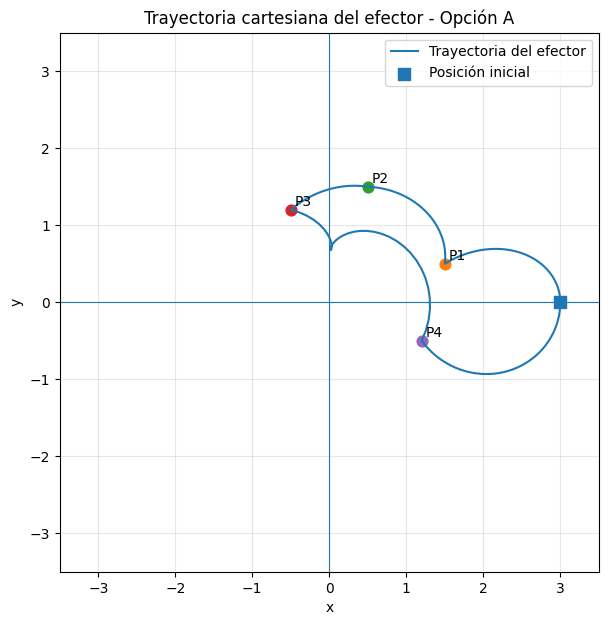


############################################################
OPCIÓN B
############################################################
OPCIÓN B
Longitud aproximada de la trayectoria: 14.719454



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(1.5, 0.5)",Convergió,3,8,9.900880e-07,"[-0.9808093280029413, 1.3181176794242, 1.23348...","[-56.19623500163097, 75.52257993258469, 70.673..."
1,2,"(0.5, 1.5)",Convergió,1,8,2.480292e-08,"[-4.288357904346119, 3.864326886716746, 1.9948...","[-245.70480896059902, 221.4096212677985, 114.2..."
2,3,"(-0.5, 1.2)",Convergió,1,7,4.506046e-12,"[-4.820272613880674, 2.5963471663727624, 3.794...","[-276.18127687785613, 148.75973478390986, 217...."
3,4,"(1.2, -0.5)",Convergió,1,18,2.885588e-10,"[-13.744541579312113, 6.847416467943696, 8.467...","[-787.5042238366591, 392.32806418155093, 485.1..."


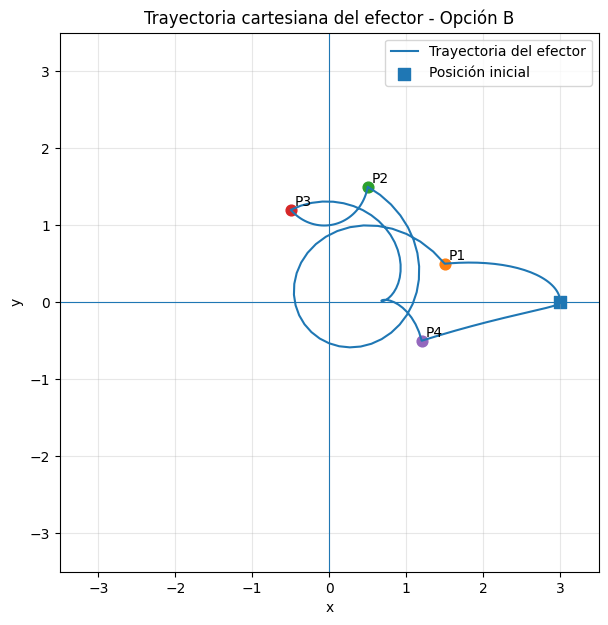


############################################################
OPCIÓN C
############################################################
OPCIÓN C
Longitud aproximada de la trayectoria: 9.663035



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(1.5, 0.5)",Convergió,1,7,1.744959e-08,"[-1.4078259735664373, 2.245927857426666, 0.0]","[-80.66248657425305, 128.68218732140764, 0.0]"
1,2,"(0.5, 1.5)",Convergió,1,7,1.516018e-11,"[-0.48053076903087505, 2.245927859730103, 0.0]","[-27.532384991644903, 128.68218745338487, 0.0]"
2,3,"(-0.5, 1.2)",Convergió,1,5,3.052141e-08,"[-0.13325449717170415, 2.545436646842141, 0.0]","[-7.634920289076613, 145.8427768819869, 0.0]"
3,4,"(1.2, -0.5)",Convergió,1,9,1.609566e-12,"[-2.4936331011292014, 2.545436658004472, 0.0]","[-142.87465234882245, 145.84277752154136, 0.0]"


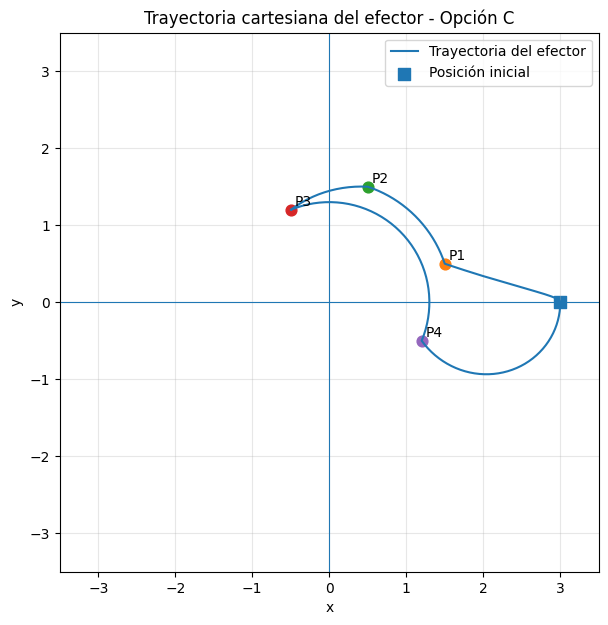


############################################################
OPCIÓN D
############################################################
OPCIÓN D
Longitud aproximada de la trayectoria: 16.550561



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(1.5, 0.5)",Convergió,1,6,1.169742e-07,"[7.880910406993749, -7.5591597864633435, -7.55...","[451.54290504146974, -433.1079524293622, -433...."
1,2,"(0.5, 1.5)",Convergió,1,5,2.125524e-11,"[8.808205531462633, -7.559159759074375, -7.559...","[504.6730020365951, -433.1079508600899, -433.1..."
2,3,"(-0.5, 1.2)",Convergió,1,5,2.595994e-12,"[9.669000807692386, -7.703413361198873, -7.703...","[553.9929383893578, -441.37307344138304, -441...."
3,4,"(1.2, -0.5)",Convergió,2,5,1.323731e-10,"[4.468166133339756, -4.862957253124928, -4.862...","[256.00706160365627, -278.6269265565903, -278...."


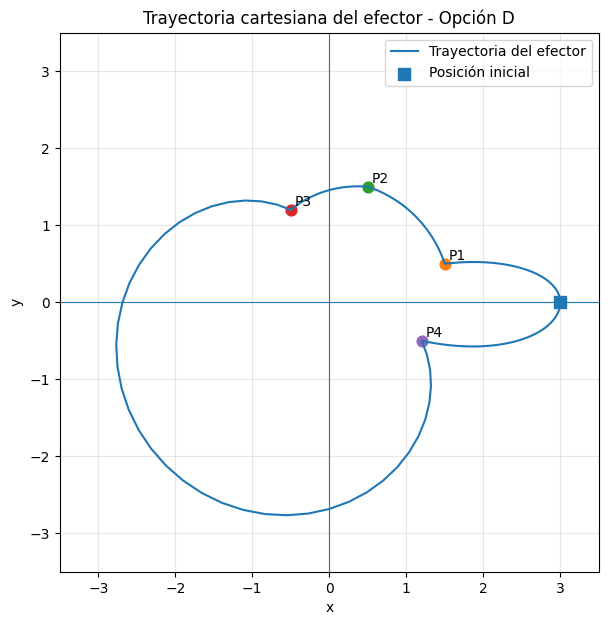


############################################################
OPCIÓN E
############################################################
OPCIÓN E
Longitud aproximada de la trayectoria: 9.445565



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(1.5, 0.5)",Convergió,1,6,3.575237e-10,"[-6.1640102697353925, 11.84363636553475, -3.78...","[-353.17177333113415, 678.5903778328027, -216...."
1,2,"(0.5, 1.5)",Convergió,1,6,4.848032e-10,"[-5.236715051544239, 11.84363636517484, -3.787...","[-300.04167096611826, 678.5903778121814, -216...."
2,3,"(-0.5, 1.2)",Convergió,1,5,1.995310e-10,"[-4.3640147159761025, 11.34781307234955, -3.44...","[-250.03962495841336, 650.1817957490132, -197...."
3,4,"(1.2, -0.5)",Convergió,1,9,1.426841e-07,"[5.8419774262579525, -13.784928394726256, 9.11...","[334.7206505352798, -789.8182179078634, 522.47..."


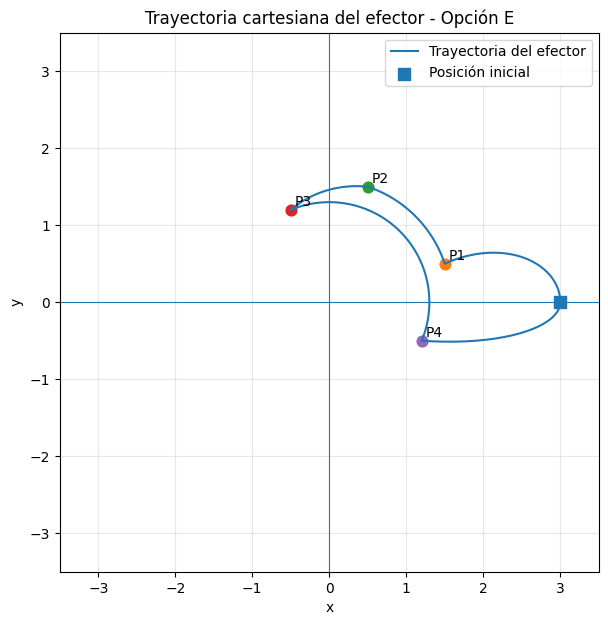

In [ ]:
# Longitudes establecidas para la Fase I
l1 = 1.0
l2 = 1.0
l3 = 1.0

# Secuencia P
puntos_P = [
    (1.5, 0.5),
    (0.5, 1.5),
    (-0.5, 1.2),
    (1.2, -0.5)
]

# Cinco ecuaciones auxiliares
opciones = [
    "A",
    "B",
    "C",
    "D",
    "E"
]

# Guardar todos los resultados
resultados_Fase_I = {}

for opcion in opciones:

    print()
    print("#" * 60)
    print(f"OPCIÓN {opcion}")
    print("#" * 60)

    resultado_fase1 = Laboratorio_Brazo_3AR(
        l1=l1,
        l2=l2,
        l3=l3,
        puntos=puntos_P,
        opcion=opcion,
        cuadros_por_tramo=40,
        tolerancia=1e-6,
        max_iter=100
    )

    resultados_Fase_I[
        opcion
    ] = resultado_fase1

    graficar_trayectoria(
        resultado_fase1,
        l1,
        l2,
        l3,
        puntos_P
    )

GIF generado: Brazo_Opcion_A.gif


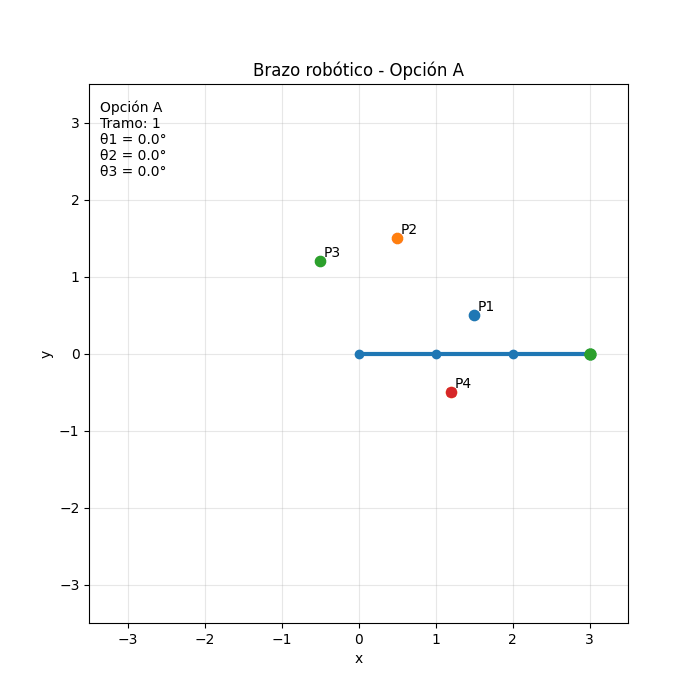

GIF generado: Brazo_Opcion_B.gif


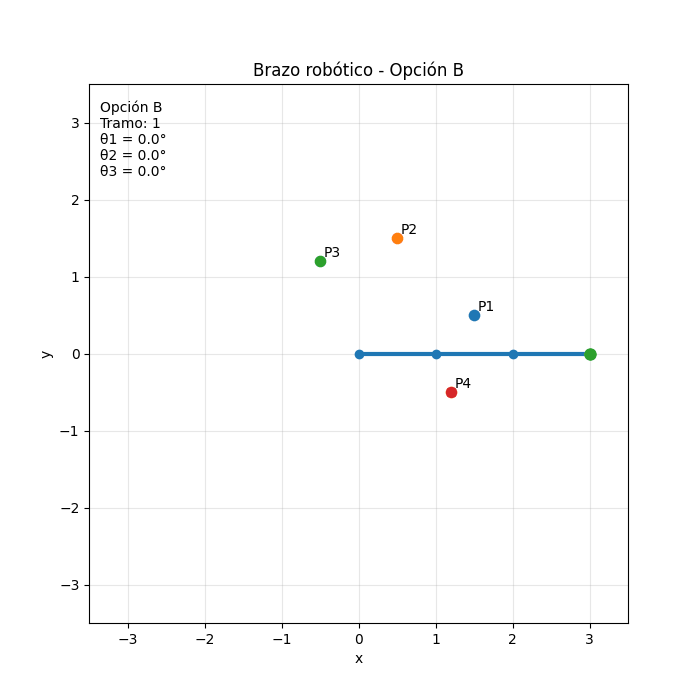

GIF generado: Brazo_Opcion_C.gif


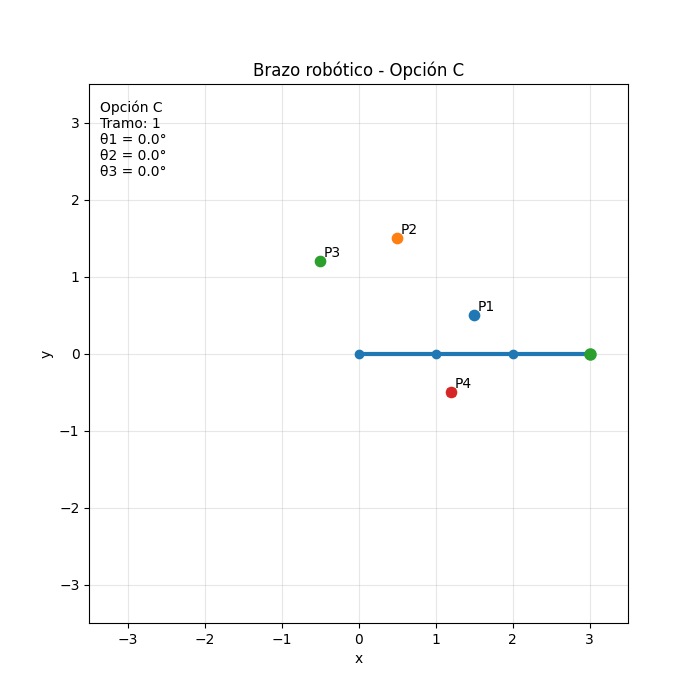

GIF generado: Brazo_Opcion_D.gif


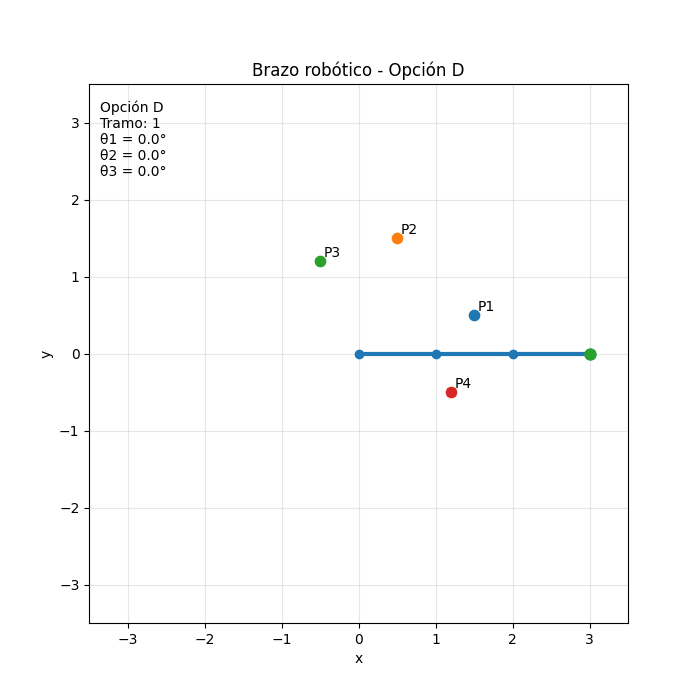

GIF generado: Brazo_Opcion_E.gif


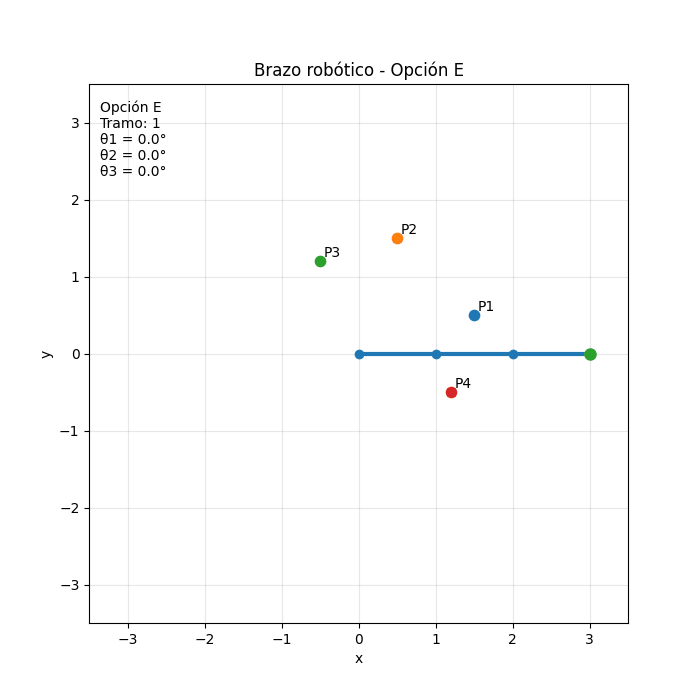

In [ ]:
archivos_gif = {}

for opcion in opciones:

    archivos_gif[opcion] = crear_animacion(
        resultados_Fase_I[opcion],
        l1,
        l2,
        l3,
        puntos_P,
        fps=20,
        mostrar=True
    )

## Influencia de la suposición inicial

Además del recorrido secuencial, se analiza el efecto de utilizar dos suposiciones iniciales diferentes para un mismo punto y una misma ecuación auxiliar.

Se utiliza el punto $P_1=(1.5,0.5)$ con la opción A y se comparan las configuraciones iniciales

$$
(0.5,0.5,-1.0)
$$

y

$$
(1.0,-0.5,-0.5).
$$

Para ambas ejecuciones se registran la convergencia, el número de iteraciones, el residuo final y la configuración angular obtenida.

In [ ]:
def resolver_con_reintentos(l1, l2, l3, x, y, opcion,
                            theta_anterior=None,
                            tolerancia=1e-6,
                            max_iter=100):
    """
    Intenta resolver el punto con distintas suposiciones iniciales.
    Primero utiliza la solución del punto anterior, si existe.
    """

    # Comprobar el alcance y la compatibilidad geométrica
    diagnostico = diagnosticar_punto(l1, l2, l3, x, y, opcion)

    if diagnostico is not None:
        return (
            None, None, 0, np.inf, False,
            None, 0, diagnostico
        )

    # Preparar las suposiciones iniciales
    candidatos = []

    if theta_anterior is not None:
        candidatos.append(
            np.asarray(theta_anterior, dtype=float)
        )

    # Para C se incluyen configuraciones con theta3 = 0
    if opcion == "C":
        candidatos.extend([
            np.array([0.5, 0.8, 0.0]),
            np.array([-0.5, 0.8, 0.0])
        ])

    candidatos.extend([
        np.array([0.5, 0.5, -1.0]),
        np.array([1.0, -0.5, -0.5]),
        np.array([-0.5, 1.0, -0.5]),
        np.array([1.0, 1.0, -1.0]),
        np.array([-1.0, 1.0, 1.0]),
        np.array([0.3, 0.8, -0.2])
    ])

    probados = []
    ultimo_resultado = None
    ultima_inicial = None

    # Probar las distintas suposiciones iniciales
    for inicial in candidatos:

        # Evitar repetir una suposición ya utilizada
        if any(np.allclose(inicial, p) for p in probados):
            continue

        probados.append(inicial.copy())
        ultima_inicial = inicial.copy()

        # Ocultar los mensajes de los intentos
        with contextlib.redirect_stdout(io.StringIO()):
            resultado = NR_Un_Punto(
                l1, l2, l3, x, y, opcion,
                theta_inicial=inicial,
                tolerancia=tolerancia,
                max_iter=max_iter
            )

        ultimo_resultado = resultado

        # Leer los datos del diccionario que devuelve Newton
        radianes = resultado["Ángulos (rad)"]
        grados = resultado["Ángulos (°)"]
        iteraciones = resultado["Iteraciones"]
        residuo = resultado["Residuo"]
        convergio = resultado["Convergió"]

        if convergio:
            return (
                radianes,
                grados,
                iteraciones,
                residuo,
                True,
                inicial.copy(),
                len(probados),
                "Convergió"
            )

    # Obtener los datos del último intento si ninguno convergió
    radianes = ultimo_resultado["Ángulos (rad)"]
    grados = ultimo_resultado["Ángulos (°)"]
    iteraciones = ultimo_resultado["Iteraciones"]
    residuo = ultimo_resultado["Residuo"]

    return (
        radianes,
        grados,
        iteraciones,
        residuo,
        False,
        ultima_inicial,
        len(probados),
        "Fallo numérico / no concluyente"
    )

### Análisis de las suposiciones iniciales

Las dos suposiciones iniciales convergieron satisfactoriamente al punto $(1.5,0.5)$ con la opción A y requirieron 8 iteraciones. En ambos casos el residuo final fue aproximadamente del orden de $10^{-12}$, por debajo de la tolerancia de $10^{-6}$.

Sin embargo, Newton-Raphson obtuvo configuraciones articulares distintas. Con la primera suposición se obtuvo aproximadamente $(114.30^\circ,-138.59^\circ,24.30^\circ)$, mientras que con la segunda se obtuvo aproximadamente $(-24.30^\circ,138.59^\circ,-114.30^\circ)$.

Ambas configuraciones satisfacen las ecuaciones de posición y la condición auxiliar A. Por lo tanto, la suposición inicial puede determinar cuál de las distintas configuraciones compatibles encuentra Newton-Raphson.

In [ ]:
comparacion_puntos = []

for opcion in opciones:

    tabla = resultados_Fase_I[
        opcion
    ]["tabla"]

    for _, fila in tabla.iterrows():

        grados = fila[
            "Ángulos (°)"
        ]

        if grados is None:

            theta1 = np.nan
            theta2 = np.nan
            theta3 = np.nan

        else:

            theta1, theta2, theta3 = np.asarray(
                grados,
                dtype=float
            )

        x, y = fila[
            "(x, y)"
        ]

        comparacion_puntos.append({
            "Opción": opcion,
            "Punto": f"P{int(fila['Punto'])}",
            "x": x,
            "y": y,
            "θ1 (°)": theta1,
            "θ2 (°)": theta2,
            "θ3 (°)": theta3,
            "Intentos": fila["Intentos"],
            "Iteraciones": fila["Iteraciones"],
            "Residuo": fila["Residuo"],
            "Estado": fila["Estado"]
        })

tabla_comparacion_puntos = pd.DataFrame(
    comparacion_puntos
)

display(
    tabla_comparacion_puntos
)

,Opción,Punto,x,y,θ1 (°),θ2 (°),θ3 (°),Intentos,Iteraciones,Residuo,Estado
0,A,P1,1.5,0.5,114.295189,-138.590378,24.295189,1,8,6.604283e-12,Convergió
1,A,P2,0.5,1.5,146.196211,-75.522512,-70.673699,1,7,3.091177e-07,Convergió
2,A,P3,-0.5,1.2,157.504230,-32.328076,-125.176154,1,5,5.701178e-08,Convergió
3,A,P4,1.2,-0.5,366.181276,-508.759735,142.578459,1,6,9.503081e-09,Convergió
4,B,P1,1.5,0.5,-56.196235,75.522580,70.673655,3,8,9.900880e-07,Convergió
5,B,P2,0.5,1.5,-245.704809,221.409621,114.295188,1,8,2.480292e-08,Convergió
6,B,P3,-0.5,1.2,-276.181277,148.759735,217.421542,1,7,4.506046e-12,Convergió
7,B,P4,1.2,-0.5,-787.504224,392.328064,485.176160,1,18,2.885588e-10,Convergió
8,C,P1,1.5,0.5,-80.662487,128.682187,0.000000,1,7,1.744959e-08,Convergió
9,C,P2,0.5,1.5,-27.532385,128.682187,0.000000,1,7,1.516018e-11,Convergió


In [ ]:
tabla_tramos_Fase_I = calcular_longitudes_por_tramo(
    resultados_Fase_I,
    l1,
    l2,
    l3,
    puntos_P,
    cuadros_por_tramo=40
)

display(
    tabla_tramos_Fase_I
)

,Opción,Tramo,Longitud aproximada
0,A,Inicio → P1,1.906223
1,A,P1 → P2,1.585279
2,A,P2 → P3,1.076454
3,A,P3 → P4,3.261968
4,A,P4 → reposo,2.467880
5,B,Inicio → P1,1.709263
6,B,P1 → P2,6.554989
7,B,P2 → P3,1.318279
8,B,P3 → P4,3.261968
9,B,P4 → reposo,1.874955


In [ ]:
resumen_Fase_I = []

for opcion in opciones:

    resultado = resultados_Fase_I[
        opcion
    ]

    tabla = resultado[
        "tabla"
    ]

    resumen_Fase_I.append({

        "Opción":
            opcion,

        "Longitud total aproximada":
            resultado["longitud"],

        "Iteraciones totales":
            tabla["Iteraciones"].sum(),

        "Iteraciones promedio":
            tabla["Iteraciones"].mean(),

        "Residuo máximo":
            tabla["Residuo"].max(),

        "Puntos convergentes":
            (
                tabla["Estado"] == "Convergió"
            ).sum()
    })

tabla_resumen_Fase_I = pd.DataFrame(
    resumen_Fase_I
)

display(
    tabla_resumen_Fase_I
)

,Opción,Longitud total aproximada,Iteraciones totales,Iteraciones promedio,Residuo máximo,Puntos convergentes
0,A,10.297803,26,6.50,3.091177e-07,4
1,B,14.719454,41,10.25,9.900880e-07,4
2,C,9.663035,28,7.00,3.052141e-08,4
3,D,16.550561,21,5.25,1.169742e-07,4
4,E,9.445565,26,6.50,1.426841e-07,4


In [ ]:
# Comprobaciones básicas de la Fase I

for opcion in opciones:

    resultado = resultados_Fase_I[
        opcion
    ]

    tabla = resultado[
        "tabla"
    ]

    # Deben existir cuatro puntos
    assert len(tabla) == 4

    # Todos los puntos de P deben converger
    assert (
        tabla["Estado"] == "Convergió"
    ).all()

    # Los residuos deben cumplir la tolerancia
    assert (
        tabla["Residuo"] <= 1e-6
    ).all()

    # La animación debe iniciar en (0,0,0)
    assert np.allclose(
        resultado["cuadros"][0],
        np.zeros(3)
    )

    # La animación debe terminar en (0,0,0)
    assert np.allclose(
        resultado["cuadros"][-1],
        np.zeros(3)
    )

print(
    "Verificación completada: "
    "las cinco opciones cumplen las condiciones comprobadas."
)

Verificación completada: las cinco opciones cumplen las condiciones comprobadas.


## Análisis comparativo de la Fase I

Los cuatro puntos de la secuencia $P$ pudieron resolverse para las cinco ecuaciones auxiliares. Aunque todas las opciones alcanzan las mismas posiciones cartesianas objetivo, las configuraciones articulares obtenidas son diferentes debido a la restricción impuesta por la tercera ecuación de cada sistema.

Las longitudes aproximadas de las trayectorias completas también presentan diferencias. Con 40 cuadros por tramo se obtuvieron aproximadamente 10.298 para A, 14.719 para B, 9.663 para C, 16.551 para D y 9.446 para E. Estas diferencias no implican que una opción sea superior a otra; muestran que cada condición auxiliar obliga al brazo a adoptar configuraciones diferentes durante las transiciones.

El análisis tramo por tramo permite identificar dónde se producen las diferencias de mayor magnitud. En la opción D, el tramo entre $P_3$ y $P_4$ presentó una longitud aproximada considerablemente mayor que los demás tramos de esa opción. En B, una diferencia importante se observó entre $P_1$ y $P_2$. Esto evidencia que dos ecuaciones auxiliares pueden alcanzar los mismos puntos y, aun así, producir recorridos cartesianos distintos debido al movimiento articular requerido entre configuraciones.

También se observaron diferencias en el comportamiento de Newton-Raphson. La opción B acumuló 41 iteraciones para los cuatro puntos, mientras que D acumuló 21. Además, para alcanzar $P_1$ con B fueron necesarios varios intentos con distintas suposiciones iniciales, y para $P_4$ con D fue necesario un reintento. Esto muestra que la convergencia depende tanto de la ecuación auxiliar como de la configuración inicial empleada.

En todas las soluciones aceptadas, el residuo final fue inferior a la tolerancia de $10^{-6}$, por lo que las configuraciones obtenidas satisfacen simultáneamente las dos ecuaciones de posición y la ecuación auxiliar correspondiente.

### Efecto de las ecuaciones auxiliares sobre el recorrido

En la **opción A**, la condición

$$
\theta_1+\theta_2+\theta_3=0
$$

mantiene el tercer eslabón con orientación horizontal. Por ello, las demás articulaciones deben compensar los cambios necesarios para alcanzar cada punto manteniendo dicha orientación.

En la **opción B**, la condición

$$
\theta_1+\theta_2+\theta_3=\frac{\pi}{2}
$$

mantiene el último eslabón con orientación vertical. Aunque las ecuaciones de posición son las mismas que en A, la orientación final impuesta produce configuraciones y recorridos distintos.

En la **opción C**, se exige

$$
\theta_3=0,
$$

por lo que los eslabones 2 y 3 permanecen alineados. En los resultados se observa que el tercer ángulo se conserva igual a cero, como requiere la ecuación auxiliar.

En la **opción D**, la condición

$$
\theta_2=\theta_3
$$

obliga a que las rotaciones relativas de las articulaciones segunda y tercera sean iguales. Los dos ángulos quedan acoplados y no pueden variar independientemente, lo cual modifica las configuraciones disponibles y la forma del recorrido.

Finalmente, en la **opción E**, la orientación del último eslabón depende del ángulo polar

$$
\alpha(x,y)=\operatorname{atan2}(y,x).
$$

La condición hace que el tercer eslabón sea tangente a la circunferencia centrada en el origen que pasa por el punto objetivo. Debido a que $\alpha$ cambia entre los diferentes puntos de la secuencia, también cambia la orientación exigida al último eslabón.

### Continuidad del movimiento y configuraciones singulares

Para favorecer la continuidad del movimiento, la solución obtenida en cada punto se utilizó como primera suposición inicial para el siguiente. Además, para la animación se seleccionaron representaciones angulares equivalentes módulo $2\pi$ que estuvieran próximas a la configuración anterior.

Esta estrategia reduce los saltos artificiales ocasionados únicamente por la representación de los ángulos. No obstante, no elimina los problemas asociados con configuraciones singulares o cercanas a singularidades.

Cuando el jacobiano es singular, el sistema lineal utilizado por Newton-Raphson no puede resolverse para obtener la corrección angular. Si se encuentra cerca de una singularidad, también pueden producirse correcciones angulares grandes o una convergencia más difícil. Por esta razón, el programa realiza varios intentos antes de clasificar un caso sin solución como un fallo numérico o no concluyente.

Es importante distinguir entre los ángulos reportados directamente por Newton-Raphson y los utilizados para visualizar la animación. Dos conjuntos de ángulos que difieren en múltiplos de $2\pi$ representan físicamente la misma configuración, por lo que el ajuste realizado para mantener la continuidad visual no modifica la postura física del brazo.

### Conclusiones de la Fase I

La función `Laboratorio_Brazo_3AR` permitió procesar secuencialmente los cuatro puntos de la Fase I para las cinco ecuaciones auxiliares. El recorrido comienza y termina en la postura articular $(0,0,0)$ y las tres articulaciones se desplazan simultáneamente durante cada transición.

Las cinco opciones alcanzaron los cuatro puntos de la secuencia, pero produjeron configuraciones articulares y trayectorias diferentes. Esto confirma que la tercera ecuación no solamente permite cerrar matemáticamente el sistema, sino que también selecciona determinadas configuraciones del brazo y modifica el movimiento necesario entre posiciones.

El uso de la solución anterior como primera suposición favoreció la continuidad del recorrido. Los reintentos con diferentes configuraciones iniciales también permitieron distinguir entre una dificultad de convergencia de Newton-Raphson y una incompatibilidad geométrica demostrable.

La comparación punto por punto, tramo por tramo, de los residuos, las iteraciones, los ángulos, las gráficas y las animaciones permitió relacionar las diferencias observadas con las restricciones impuestas por cada ecuación auxiliar.

## **Fase II: compatibilidad de los puntos de Q con las opciones A–E**

In [ ]:
# Longitudes indicadas
l1 = l2 = l3 = 1

# Puntos de la Fase II en orden
puntos_Q = [
    (0.5, 0.5),
    (1.3, 1.3),
    (-1.4, 0.3),
    (0.3, -1.4)]

# Condiciones auxiliares que vamos a evaluar
opciones = ["A", "B", "C", "D", "E"]

In [ ]:
def compatibilidad_Fase_II(x, y, opcion):
    # En esta fase, las tres longitudes son iguales a 1
    if opcion == "A":
        return verificar_compatibilidad_A(1, 1, 1, x, y)

    elif opcion == "B":
        return verificar_compatibilidad_B(1, 1, 1, x, y)

    elif opcion == "C":
        return verificar_compatibilidad_C(1, 1, 1, x, y)

    elif opcion == "D":
        return verificar_alcance(1, 1, 1, x, y)

    elif opcion == "E":
        return verificar_compatibilidad_E(1, 1, 1, x, y)

    else:
        raise ValueError("Opción no válida.")

In [ ]:
resultados_Q = []

for opcion in opciones:
    # Elegir la suposición inicial para cada opción
  if opcion == "C":
        inicial = np.array([0.5, 0.8, 0.0])
  else:
        inicial = np.array([0.5, 0.5, -1.0])

  for x, y in puntos_Q:
        compatible = compatibilidad_Fase_II(x, y, opcion)
        resultado = NR_Un_Punto(
            l1, l2, l3, x, y, opcion,
            theta_inicial=inicial
        )

        radianes = resultado["Ángulos (rad)"]
        grados = resultado["Ángulos (°)"]
        iteraciones = resultado["Iteraciones"]
        residuo = resultado["Residuo"]
        convergio = resultado["Convergió"]
        if not compatible:
            estado = "Incompatible"
        elif convergio:
            estado = "Convergió"
        else:
            estado = "Fallo numérico"

        resultados_Q.append({
            "Opción": opcion,
            "Punto": (x, y),
            "Compatible": compatible,
            "Estado": estado,
            "Iteraciones": iteraciones,
            "Residuo": residuo,
            "Ángulos (rad)": radianes,
            "Ángulos (°)": grados})

        # Usar la última solución válida para el siguiente punto
        if convergio:
            inicial = radianes.copy()

In [ ]:
import pandas as pd

tabla_Q = pd.DataFrame(resultados_Q)

display(tabla_Q[
    ["Opción", "Punto", "Compatible", "Estado",
     "Iteraciones", "Residuo", "Ángulos (rad)", "Ángulos (°)"]])

,Opción,Punto,Compatible,Estado,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,A,"(0.5, 0.5)",True,Convergió,7,4.447986e-10,"[-2.717561613428393, 10.147512208382496, -7.42...","[-155.70481101620945, 581.4096220977946, -425...."
1,A,"(1.3, 1.3)",True,Convergió,6,7.469193e-09,"[-4.09867813253252, 10.88535123085818, -6.7866...","[-234.83695857667524, 623.6846840457096, -388...."
2,A,"(-1.4, 0.3)",False,Incompatible,0,inf,None,None
3,A,"(0.3, -1.4)",True,Convergió,6,1.201247e-10,"[-2.7063705811384677, 7.627038597953623, -4.92...","[-155.06361209760212, 436.99712184611934, -281..."
4,B,"(0.5, 0.5)",True,Convergió,14,1.657064e-11,"[6.707216346691538, -8.702043712970084, 3.5656...","[384.2951889465799, -498.5903778915382, 204.29..."
5,B,"(1.3, 1.3)",True,Convergió,6,7.469193e-09,"[7.350493842828409, -7.964204690680579, 2.1845...","[421.1522745309657, -456.31531595429044, 125.1..."
6,B,"(-1.4, 0.3)",True,Convergió,6,1.201245e-10,"[9.216498924338914, -11.222517323585137, 3.576...","[528.0664902514828, -643.0028781538807, 204.93..."
7,B,"(0.3, -1.4)",False,Incompatible,0,inf,None,None
8,C,"(0.5, 0.5)",False,Incompatible,0,inf,None,None
9,C,"(1.3, 1.3)",True,Convergió,5,5.720826e-07,"[-0.6818667056056148, 1.9877752424061865, 0.0]","[-39.06808442169112, 113.89113201046862, 0.0]"


In [ ]:
resultado_D = NR_Un_Punto(
    1, 1, 1, 0.3, -1.4, "D",
    theta_inicial=(-1.0, 1.0, 1.0)
)

print("Punto objetivo:", resultado_D["Punto"])
print("Opción utilizada:", resultado_D["Opción"])
print("¿Convergió?:", resultado_D["Convergió"])
print("Ángulos en radianes:", resultado_D["Ángulos (rad)"])
print("Ángulos en grados:", resultado_D["Ángulos (°)"])
print("Correcciones realizadas:", resultado_D["Iteraciones"])
print("Residuo final:", resultado_D["Residuo"])
print("Mensaje:", resultado_D["Mensaje"])

Punto objetivo: (0.3, -1.4)
Opción utilizada: D
¿Convergió?: True
Ángulos en radianes: [-15.27926562   1.35319201   1.35319201]
Ángulos en grados: [-875.43743425   77.53219133   77.53219133]
Correcciones realizadas: 6
Residuo final: 1.0481061631905591e-10
Mensaje: Convergió: el residuo cumple la tolerancia


### Reintento del punto (0.3, -1.4) con la opción D

Al usar la solución del punto anterior como suposición inicial, se agotaron las 100 iteraciones sin converger.

Al repetir el cálculo con la suposición inicial (-1, 1, 1)
radianes, convergió en 6 iteraciones, con un residuo aproximado
de 1.05 × 10⁻¹⁰, inferior a la tolerancia de 10⁻⁶.
Los ángulos θ₂ y θ₃ resultaron iguales, cumpliendo la condición D.

Esto confirma que el primer fallo fue numérico y que el punto
es compatible con la opción D.

In [ ]:
# Actualizar la fila de D si el reintento convergió
if resultado_D["Convergió"]:
    for fila in resultados_Q:
        if fila["Opción"] == "D" and fila["Punto"] == (0.3, -1.4):
            fila["Estado"] = "Convergió después de un reintento"
            fila["Compatible"] = True
            fila["Iteraciones"] = resultado_D["Iteraciones"]
            fila["Residuo"] = resultado_D["Residuo"]
            fila["Ángulos (rad)"] = resultado_D["Ángulos (rad)"]
            fila["Ángulos (°)"] = resultado_D["Ángulos (°)"]
            break

# Mostrar la tabla con los resultados finales
tabla_Q = pd.DataFrame(resultados_Q)
display(tabla_Q)

,Opción,Punto,Compatible,Estado,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,A,"(0.5, 0.5)",True,Convergió,7,4.447986e-10,"[-2.717561613428393, 10.147512208382496, -7.42...","[-155.70481101620945, 581.4096220977946, -425...."
1,A,"(1.3, 1.3)",True,Convergió,6,7.469193e-09,"[-4.09867813253252, 10.88535123085818, -6.7866...","[-234.83695857667524, 623.6846840457096, -388...."
2,A,"(-1.4, 0.3)",False,Incompatible,0,inf,None,None
3,A,"(0.3, -1.4)",True,Convergió,6,1.201247e-10,"[-2.7063705811384677, 7.627038597953623, -4.92...","[-155.06361209760212, 436.99712184611934, -281..."
4,B,"(0.5, 0.5)",True,Convergió,14,1.657064e-11,"[6.707216346691538, -8.702043712970084, 3.5656...","[384.2951889465799, -498.5903778915382, 204.29..."
5,B,"(1.3, 1.3)",True,Convergió,6,7.469193e-09,"[7.350493842828409, -7.964204690680579, 2.1845...","[421.1522745309657, -456.31531595429044, 125.1..."
6,B,"(-1.4, 0.3)",True,Convergió,6,1.201245e-10,"[9.216498924338914, -11.222517323585137, 3.576...","[528.0664902514828, -643.0028781538807, 204.93..."
7,B,"(0.3, -1.4)",False,Incompatible,0,inf,None,None
8,C,"(0.5, 0.5)",False,Incompatible,0,inf,None,None
9,C,"(1.3, 1.3)",True,Convergió,5,5.720826e-07,"[-0.6818667056056148, 1.9877752424061865, 0.0]","[-39.06808442169112, 113.89113201046862, 0.0]"


### Interpretación de la tabla final

Para la opción D y el punto (0.3, -1.4), el primer intento alcanzó el máximo de 100 iteraciones sin converger. Al repetir el cálculo con los ángulos iniciales (-1, 1, 1) radianes, se obtuvo convergencia en 6 correcciones.

La tabla final muestra las iteraciones, el residuo y los ángulos del reintento exitoso. Las 6 correcciones corresponden únicamente a ese segundo intento.

Este resultado demuestra que la elección de los ángulos iniciales influye en la convergencia de Newton-Raphson. Un fallo numérico por sí solo no demuestra que el punto sea incompatible.

## Justificación geométrica de los casos incompatibles

### Opción A: punto (-1.4, 0.3)

La opción A exige que el último segmento apunte hacia la derecha.
Como su longitud es 1, la unión entre el segundo y el tercer
segmento debe estar en (-2.4, 0.3).

La distancia de esa unión al origen es aproximadamente 2.419.
Los primeros dos segmentos solo pueden alcanzar una distancia
máxima de 2, porque ambos tienen longitud 1.

Por tanto, este punto es incompatible con A, aunque está dentro
del alcance general del brazo.

### Opción B: punto (0.3, -1.4)

La opción B exige que el último segmento apunte hacia arriba, como su longitud es 1, la unión entre el segundo y el tercer
segmento debe estar en (0.3, -2.4).

La distancia de esa unión al origen es aproximadamente 2.419.
Los primeros dos segmentos solo pueden alcanzar una distancia
máxima de 2.

Por tanto, este punto es incompatible con B, aunque está dentro
del alcance general del brazo.

### Opción C: punto (0.5, 0.5)

La opción C exige que θ₃ = 0, por lo que el segundo y el tercer
segmento quedan alineados en el mismo sentido. Juntos equivalen
a un segmento de longitud 2.

El brazo se comporta entonces como uno de dos segmentos,
con longitudes 1 y 2. Su distancia mínima al origen es
|2 − 1| = 1 y su distancia máxima es 3.

El punto (0.5, 0.5) está a una distancia aproximada de 0.707
del origen, menor que 1. Por tanto, es incompatible con C.

### Opción E: punto (1.3, 1.3)

La opción E exige que el último segmento sea perpendicular
a la dirección que va del origen al punto objetivo.

La distancia del punto al origen es r = √(1.3² + 1.3²).
Como el último segmento tiene longitud 1 y es perpendicular
a esa dirección, la distancia de su unión al origen es:

d = √(r² + 1) = √4.38 ≈ 2.093.

Los primeros dos segmentos solo pueden alcanzar una distancia
máxima de 2. Por tanto, el punto es incompatible con E,
aunque está dentro del alcance general del brazo.

## Parámetros y criterio de parada de Newton-Raphson

Se utiliza una tolerancia de 10⁻⁶ y se considera que el método
convergió cuando la norma euclídea del residuo cumple
‖F(θ)‖₂ ≤ 10⁻⁶. Esto comprueba conjuntamente las
dos ecuaciones de posición y la condición auxiliar.

La tolerancia elegida permite obtener residuos pequeños
para los experimentos del laboratorio. No representa
directamente el error de los ángulos.

Se permiten como máximo 100 correcciones para limitar
el trabajo del método cuando no converge. Si se alcanza
ese límite sin cumplir la tolerancia, se informa un fallo
numérico; esto no demuestra incompatibilidad geométrica.

También se detiene el cálculo si el jacobiano es singular
y no se puede resolver el sistema para obtener la corrección.

## Gráficas y animaciones de la secuencia Q para las opciones A–E

Se reutilizan las funciones de Alison para visualizar los recorridos de la Fase II. Cuando un punto no puede alcanzarse, el brazo conserva la última configuración válida y continúa con el siguiente objetivo, respetando el orden de Q.


FASE II — SECUENCIA Q — OPCIÓN A
OPCIÓN A
Longitud aproximada de la trayectoria: 26.826313



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(0.5, 0.5)",Convergió,1,7,4.447986e-10,"[-2.717561613428393, 10.147512208382496, -7.42...","[-155.70481101620945, 581.4096220977946, -425...."
1,2,"(1.3, 1.3)",Convergió,1,6,7.469193e-09,"[-4.09867813253252, 10.88535123085818, -6.7866...","[-234.83695857667524, 623.6846840457096, -388...."
2,3,"(-1.4, 0.3)",Incompatible con la opción A,0,0,inf,None,None
3,4,"(0.3, -1.4)",Convergió,1,6,1.201247e-10,"[-2.7063705811384677, 7.627038597953623, -4.92...","[-155.06361209760212, 436.99712184611934, -281..."


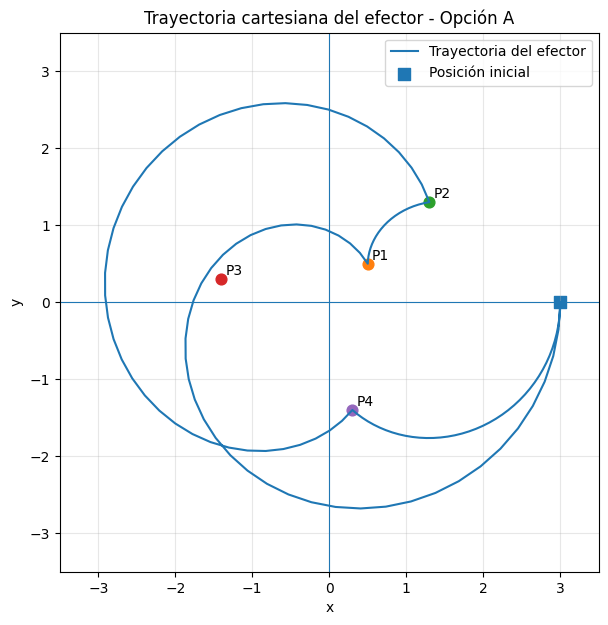

GIF generado: Brazo_Opcion_A.gif


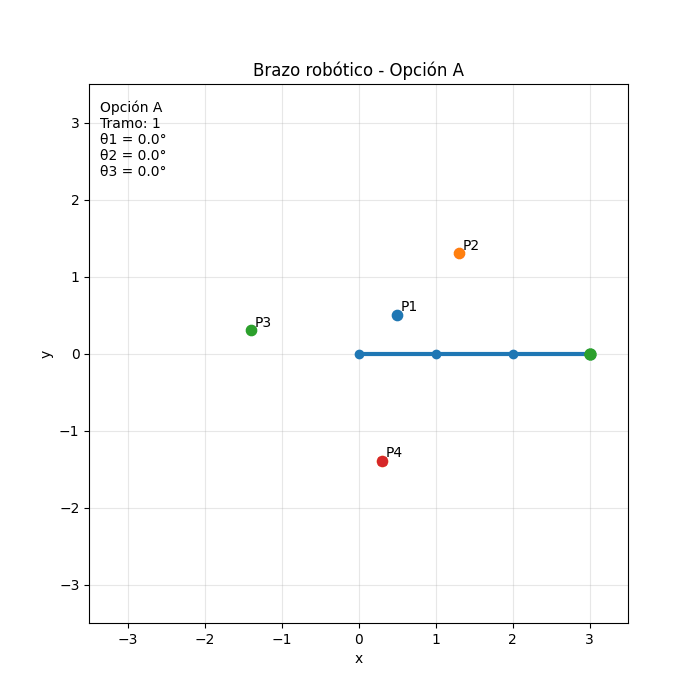


FASE II — SECUENCIA Q — OPCIÓN B
OPCIÓN B
Longitud aproximada de la trayectoria: 17.477764



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(0.5, 0.5)",Convergió,1,14,1.657064e-11,"[6.707216346691538, -8.702043712970084, 3.5656...","[384.2951889465799, -498.5903778915382, 204.29..."
1,2,"(1.3, 1.3)",Convergió,1,6,7.469193e-09,"[7.350493842828409, -7.964204690680579, 2.1845...","[421.1522745309657, -456.31531595429044, 125.1..."
2,3,"(-1.4, 0.3)",Convergió,1,6,1.201245e-10,"[9.216498924338914, -11.222517323585137, 3.576...","[528.0664902514828, -643.0028781538807, 204.93..."
3,4,"(0.3, -1.4)",Incompatible con la opción B,0,0,inf,None,None


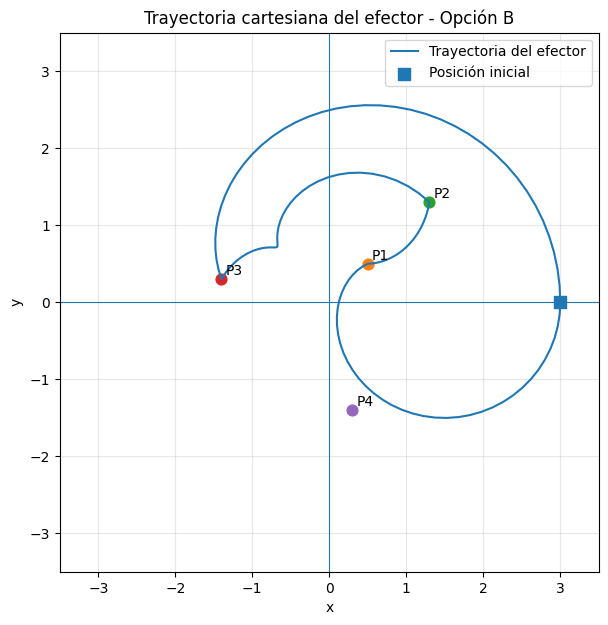

GIF generado: Brazo_Opcion_B.gif


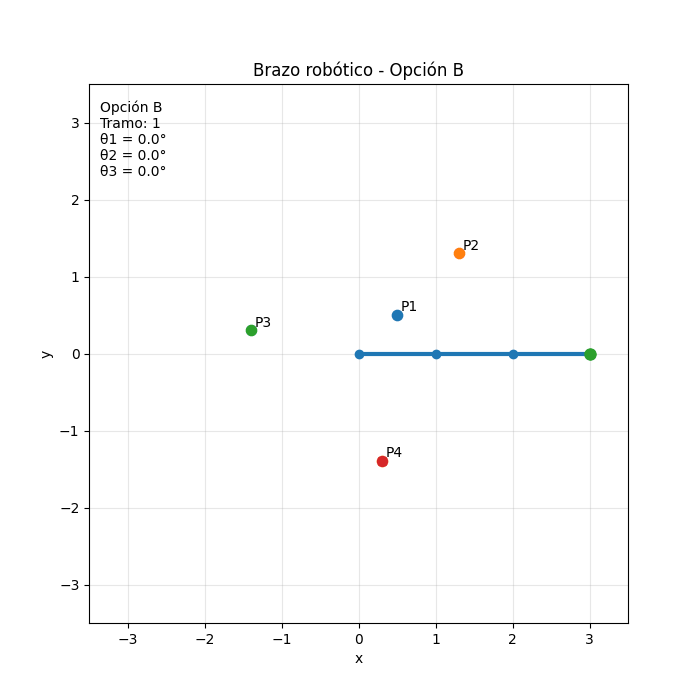


FASE II — SECUENCIA Q — OPCIÓN C
OPCIÓN C
Longitud aproximada de la trayectoria: 11.712437



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(0.5, 0.5)",Incompatible con la opción C,0,0,inf,None,None
1,2,"(1.3, 1.3)",Convergió,1,5,5.720826e-07,"[-0.6818667056056148, 1.9877752424061865, 0.0]","[-39.06808442169112, 113.89113201046862, 0.0]"
2,3,"(-1.4, 0.3)",Convergió,1,6,2.888205e-11,"[-1.4437269776525319, 3.883027943187429, 0.0]","[-82.7194625886682, 222.4811128760045, 0.0]"
3,4,"(0.3, -1.4)",Convergió,1,6,2.684383e-09,"[0.5492560184312464, 3.8830279404537555, 0.0]","[31.470051728270175, 222.48111271937654, 0.0]"


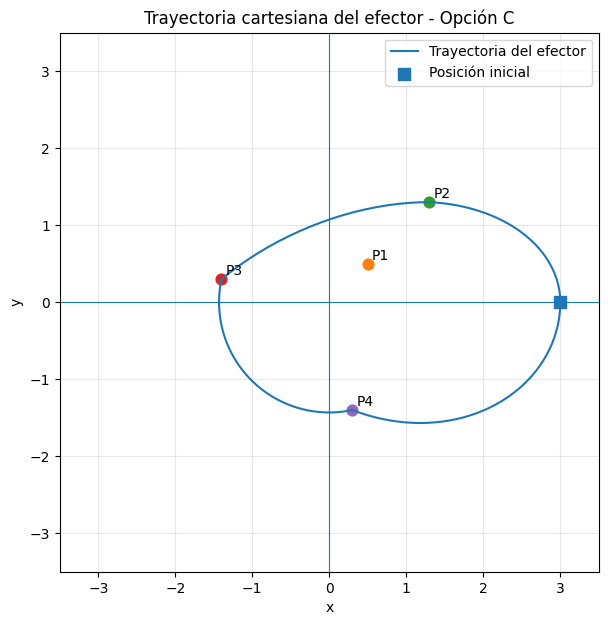

GIF generado: Brazo_Opcion_C.gif


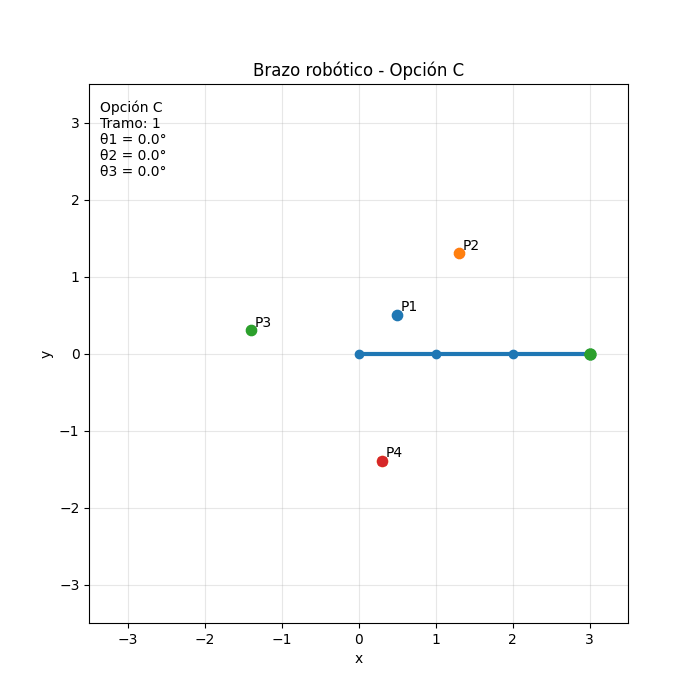


FASE II — SECUENCIA Q — OPCIÓN D
OPCIÓN D
Longitud aproximada de la trayectoria: 22.675583



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(0.5, 0.5)",Convergió,1,6,2.222936e-08,"[5.350811943227847, -4.5654137784955005, -4.56...","[306.5789413151503, -261.57894123866623, -261...."
1,2,"(1.3, 1.3)",Convergió,1,3,7.751845e-11,"[5.93039387796293, -5.144995714565482, -5.1449...","[339.7865400574973, -294.7865400574973, -294.7..."
2,3,"(-1.4, 0.3)",Convergió,1,37,6.363588e-09,"[26.71004852884726, -4.929993291063548, -4.929...","[1530.3730512925615, -282.4678086057521, -282...."
3,4,"(0.3, -1.4)",Convergió,2,6,4.178024e-09,"[6.276674332112381, -7.636377323472223, -7.636...","[359.6269486081342, -437.5321914043662, -437.5..."


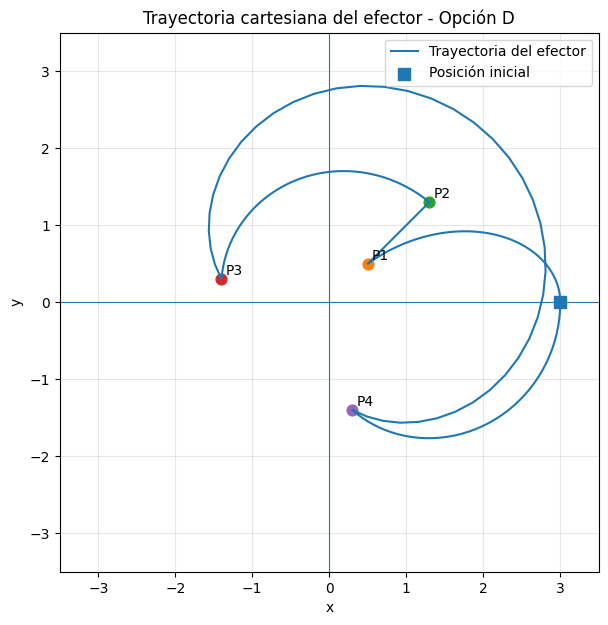

GIF generado: Brazo_Opcion_D.gif


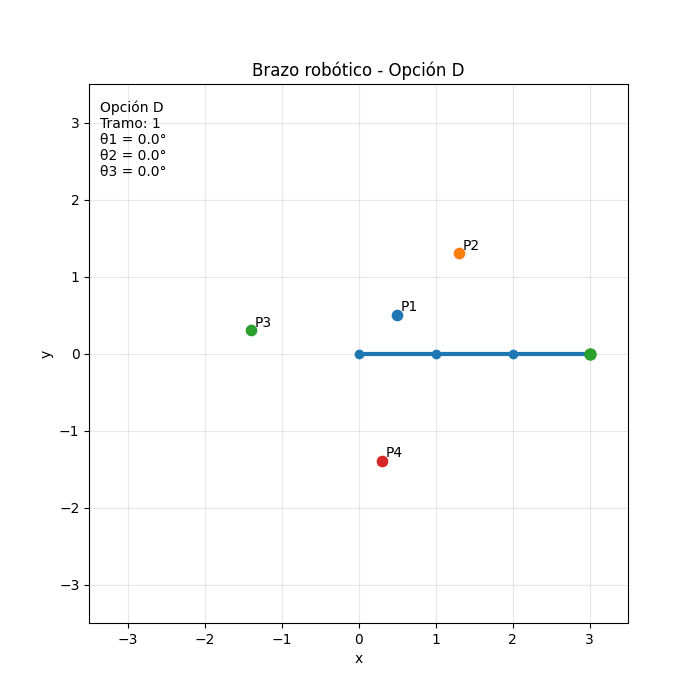


FASE II — SECUENCIA Q — OPCIÓN E
OPCIÓN E
Longitud aproximada de la trayectoria: 14.883709



,Punto,"(x, y)",Estado,Intentos,Iteraciones,Residuo,Ángulos (rad),Ángulos (°)
0,1,"(0.5, 0.5)",Convergió,1,5,3.513579e-07,"[-7.364841988497383, 14.38984749379732, -4.668...","[-421.9743627216368, 824.4775292314915, -267.5..."
1,2,"(1.3, 1.3)",Incompatible con la opción E,0,0,inf,None,None
2,3,"(-1.4, 0.3)",Convergió,1,12,1.641123e-10,"[27.96260946157492, 17.831474707508818, -41.29...","[1602.1395063208263, 1021.6682432345293, -2365..."
3,4,"(0.3, -1.4)",Convergió,1,10,6.430288e-10,"[61.37151899125428, -51.28356367242407, -9.876...","[3516.3290205058497, -2938.331756820328, -565...."


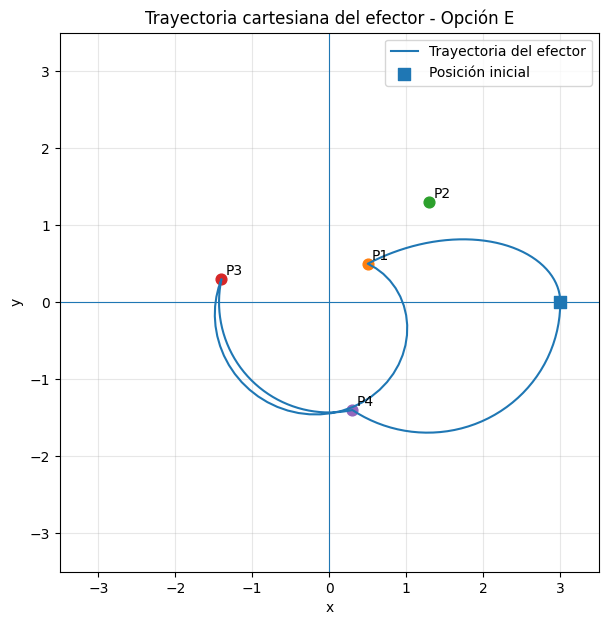

GIF generado: Brazo_Opcion_E.gif


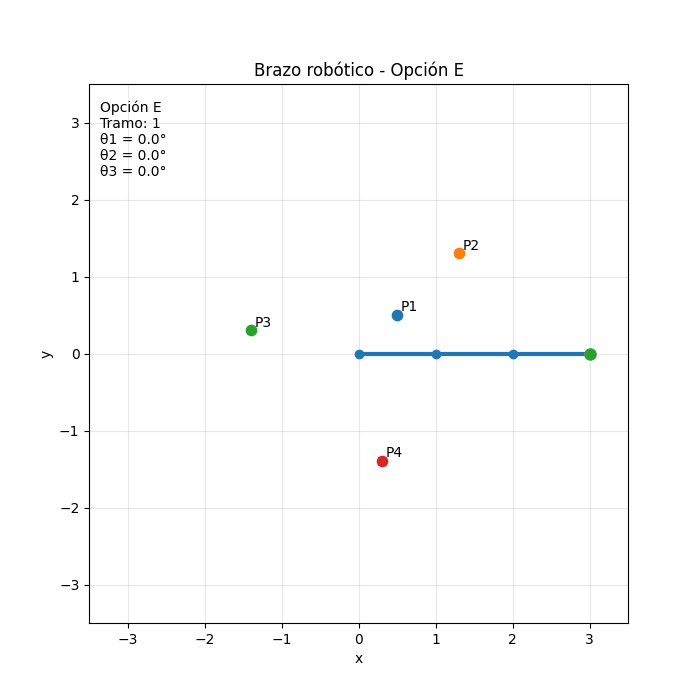

In [ ]:
# Gráficas y GIF de Q reutilizando las funciones de Alison
import os

resultados_Fase_II = {}
archivos_graficas_Q = {}
archivos_gif_Q = {}

# Carpeta diferente para no sobrescribir los archivos de la Fase I
carpeta_original = os.getcwd()
carpeta_Q = os.path.join(carpeta_original, "Graficas_GIF_Q")
os.makedirs(carpeta_Q, exist_ok=True)

try:
    os.chdir(carpeta_Q)

    for opcion in ["A", "B", "C", "D", "E"]:

        print(f"\nFASE II — SECUENCIA Q — OPCIÓN {opcion}")

        resultado_Q = Laboratorio_Brazo_3AR(
            l1=1.0,
            l2=1.0,
            l3=1.0,
            puntos=puntos_Q,
            opcion=opcion,
            cuadros_por_tramo=40,
            tolerancia=1e-6,
            max_iter=100
        )

        resultados_Fase_II[opcion] = resultado_Q

        archivos_graficas_Q[opcion] = graficar_trayectoria(
            resultado_Q, 1.0, 1.0, 1.0, puntos_Q
        )

        archivos_gif_Q[opcion] = crear_animacion(
            resultado_Q, 1.0, 1.0, 1.0, puntos_Q,
            fps=20,
            mostrar=True
        )

finally:
    os.chdir(carpeta_original)

# **Fase III: Mapas del espacio de trabajo**
##Alternativa seleccionada:
Para construir los mapas del espacio de trabajo se seleccionó la Alternativa 1: exploración de una cuadrícula cartesiana mediante Newton-Raphson. Se escogió esta opción porque permite reutilizar directamente la función NR_Un_Punto desarrollada anteriormente y mantiene el análisis relacionado con el método numérico principal del laboratorio. Para cada punto de la cuadrícula se probarán varias suposiciones iniciales y se considerará que el punto fue encontrado cuando al menos una de ellas produzca una solución con un residuo menor o igual a la tolerancia establecida. Aunque esta alternativa tiene un mayor costo computacional debido a la cantidad de puntos que deben evaluarse, su implementación es coherente con el resto del proyecto y permite comparar las cinco ecuaciones auxiliares utilizando los mismos criterios. Se debe tomar en cuenta que una celda que no sea coloreada indica únicamente que Newton-Raphson no encontró una solución con los intentos realizados, por lo que no se puede considerar automáticamente como un punto incompatible.

###Parámetros de la fase III

In [ ]:
# FASE III: MAPAS DEL ESPACIO DE TRABAJO
# Alternativa 1: cuadrícula cartesiana con Newton-Raphson

# Longitudes establecidas para esta fase
l1 = l2 = l3 = 1.0

# Cinco ecuaciones auxiliares
opciones_Fase_III = ["A", "B", "C", "D", "E"]

# Límites del dominio cartesiano
limite_mapa = 3.0

# Resolución de la cuadrícula
resolucion_mapa = 101

# Parámetros numéricos
tolerancia_mapa = 1e-6
max_iter_mapa = 100

# Suposiciones iniciales que se probarán en cada punto
suposiciones_mapa = [
    np.array([0.5, 0.5, -1.0]),
    np.array([1.0, -0.5, -0.5]),
    np.array([-0.5, 1.0, -0.5]),
    np.array([1.0, 1.0, -1.0]),
    np.array([-1.0, 1.0, 1.0]),
    np.array([0.3, 0.8, -0.2])
]

###Probar un punto del mapa

In [ ]:
def probar_punto_mapa(x, y, opcion):
    """
    Prueba varias suposiciones iniciales para encontrar
    una configuración compatible con el punto.
    """

    if not verificar_alcance(l1, l2, l3, x, y):
        return False, np.inf, 0, None

    mejor_residuo = np.inf

    for numero_intento, inicial in enumerate(
        suposiciones_mapa, start=1
    ):

        with contextlib.redirect_stdout(io.StringIO()):
            resultado = NR_Un_Punto(
                l1,
                l2,
                l3,
                x,
                y,
                opcion,
                theta_inicial=inicial,
                tolerancia=tolerancia_mapa,
                max_iter=max_iter_mapa
            )

        radianes = resultado["Ángulos (rad)"]
        residuo = resultado["Residuo"]
        convergio = resultado["Convergió"]

        if np.isfinite(residuo):
            mejor_residuo = min(mejor_residuo, residuo)

        if convergio and residuo <= tolerancia_mapa:
            return True, residuo, numero_intento, radianes

    return False, mejor_residuo, len(suposiciones_mapa), None

###Construcción de los cinco mapas

In [ ]:
# Coordenadas de la cuadrícula
coordenadas = np.linspace(
    -limite_mapa,
    limite_mapa,
    resolucion_mapa
)

# Aquí se guardarán los cinco mapas
mapas_Fase_III = {}

# También se guarda el mejor residuo encontrado en cada punto
residuos_Fase_III = {}

for opcion in opciones_Fase_III:

    print(f"Calculando mapa de la opción {opcion}...")

    # Matriz de 0 y 1
    matriz_alcance = np.zeros(
        (resolucion_mapa, resolucion_mapa),
        dtype=int
    )

    # Matriz para conservar residuos
    matriz_residuos = np.full(
        (resolucion_mapa, resolucion_mapa),
        np.nan
    )

    # Recorrer todos los puntos de la cuadrícula
    for fila, y in enumerate(coordenadas):

        for columna, x in enumerate(coordenadas):

            (
                encontrado,
                residuo,
                intentos,
                angulos
            ) = probar_punto_mapa(
                x,
                y,
                opcion
            )

            # 1 = Newton encontró una solución
            # 0 = no encontró solución con los intentos realizados
            if encontrado:
                matriz_alcance[fila, columna] = 1

            if np.isfinite(residuo):
                matriz_residuos[fila, columna] = residuo

    mapas_Fase_III[opcion] = matriz_alcance
    residuos_Fase_III[opcion] = matriz_residuos

    print(
        "Celdas alcanzadas:",
        int(np.sum(matriz_alcance))
    )

    print()

Calculando mapa de la opción A...
Celdas alcanzadas: 3495

Calculando mapa de la opción B...
Celdas alcanzadas: 3495

Calculando mapa de la opción C...
Celdas alcanzadas: 6968

Calculando mapa de la opción D...
Celdas alcanzadas: 7666

Calculando mapa de la opción E...
Celdas alcanzadas: 2617



###Función para dibujar los mapas y mostrarlos


In [ ]:
def graficar_mapa_Fase_III(opcion, matriz, guardar=True):

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    # Región donde Newton encontró una configuración
    ax.imshow(
        matriz,
        extent=[
            -limite_mapa,
            limite_mapa,
            -limite_mapa,
            limite_mapa
        ],
        origin="lower",
        cmap="Blues",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    # Circunferencia de alcance geométrico general
    angulo = np.linspace(
        0,
        2*np.pi,
        400
    )

    radio_maximo = l1 + l2 + l3

    ax.plot(
        radio_maximo*np.cos(angulo),
        radio_maximo*np.sin(angulo),
        "--",
        linewidth=1.5,
        label="Frontera geométrica r = 3"
    )

    # Ejes cartesianos
    ax.axhline(
        0,
        linewidth=0.8
    )

    ax.axvline(
        0,
        linewidth=0.8
    )

    # Marcar el origen
    ax.scatter(
        0,
        0,
        s=35,
        label="Origen"
    )

    # Límites iguales para todos los mapas
    ax.set_xlim(
        -limite_mapa,
        limite_mapa
    )

    ax.set_ylim(
        -limite_mapa,
        limite_mapa
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax.set_title(
        f"Mapa del espacio de trabajo - Opción {opcion}"
    )

    ax.legend(
        loc="upper right"
    )

    if guardar:

        plt.savefig(
            f"Mapa_Fase_III_{opcion}.png",
            dpi=200,
            bbox_inches="tight"
        )

    plt.show()



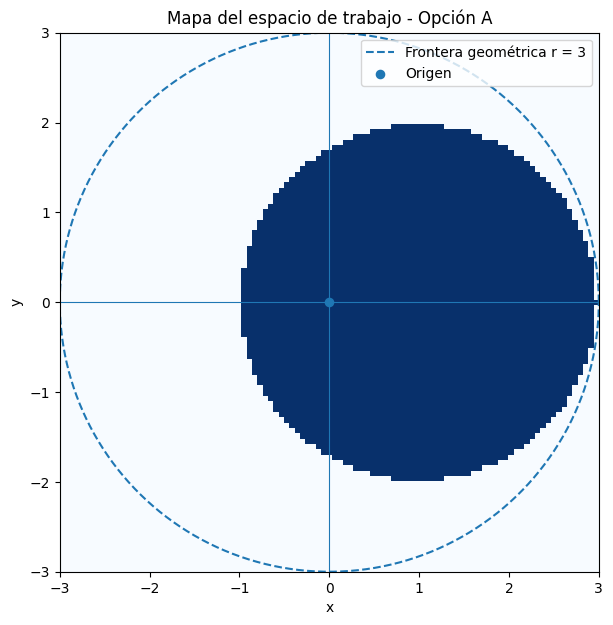

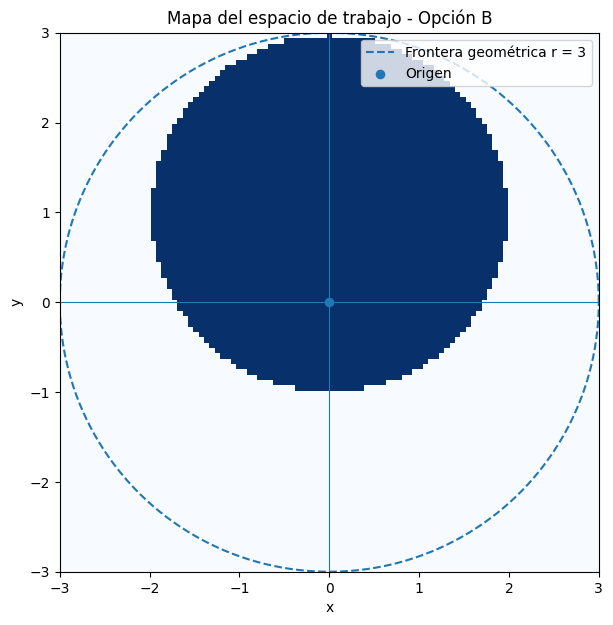

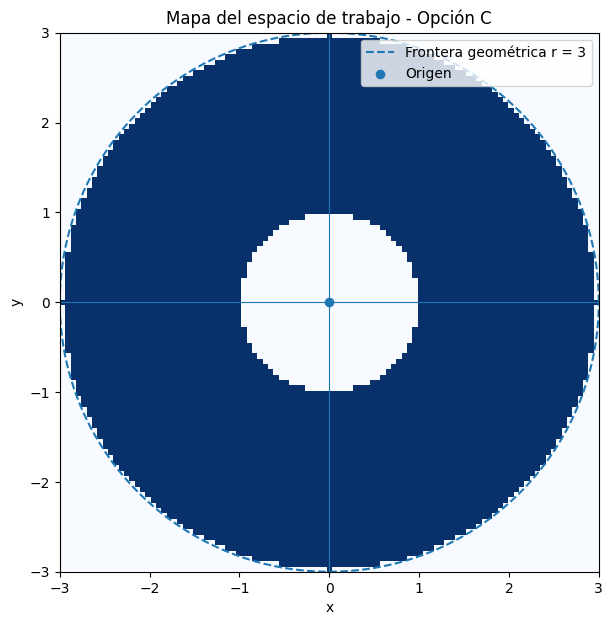

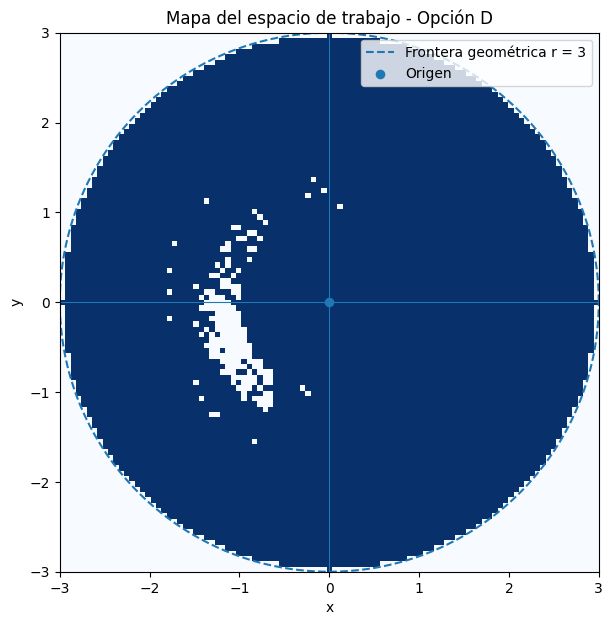

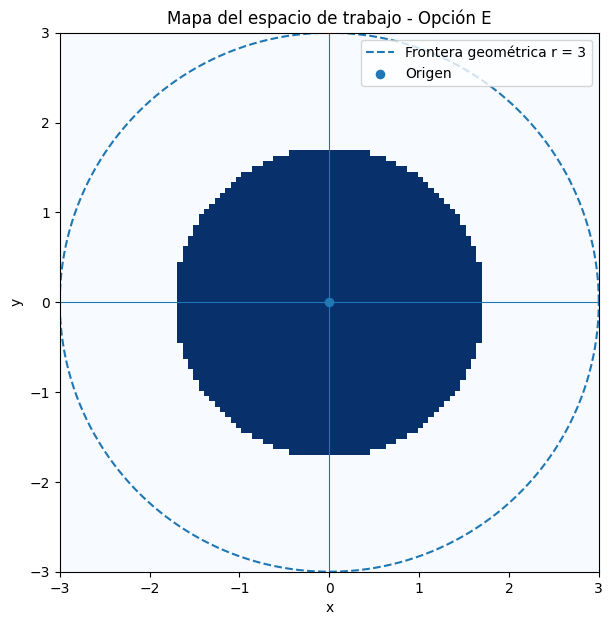

In [ ]:
for opcion in opciones_Fase_III:

    graficar_mapa_Fase_III(
        opcion,
        mapas_Fase_III[opcion]
    )

###Figura comparativa

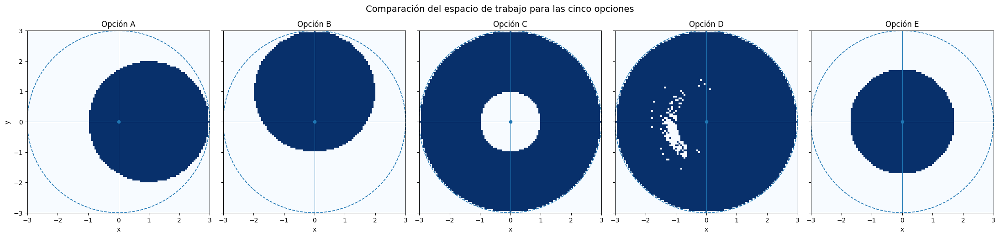

In [ ]:
fig, ejes = plt.subplots(
    1,
    5,
    figsize=(22, 5),
    sharex=True,
    sharey=True
)

angulo = np.linspace(
    0,
    2*np.pi,
    400
)

radio_maximo = l1 + l2 + l3

for ax, opcion in zip(
    ejes,
    opciones_Fase_III
):

    ax.imshow(
        mapas_Fase_III[opcion],
        extent=[
            -limite_mapa,
            limite_mapa,
            -limite_mapa,
            limite_mapa
        ],
        origin="lower",
        cmap="Blues",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    # Frontera geométrica general
    ax.plot(
        radio_maximo*np.cos(angulo),
        radio_maximo*np.sin(angulo),
        "--",
        linewidth=1.2
    )

    # Ejes
    ax.axhline(
        0,
        linewidth=0.7
    )

    ax.axvline(
        0,
        linewidth=0.7
    )

    ax.scatter(
        0,
        0,
        s=20
    )

    ax.set_xlim(
        -limite_mapa,
        limite_mapa
    )

    ax.set_ylim(
        -limite_mapa,
        limite_mapa
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.set_title(
        f"Opción {opcion}"
    )

    ax.set_xlabel("x")

ejes[0].set_ylabel("y")

fig.suptitle(
    "Comparación del espacio de trabajo para las cinco opciones",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "Comparacion_Mapas_Fase_III.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

###Interpretación de los mapas obtenidos

**Opción A:** En la opción A se observa una región circular desplazada hacia el lado derecho del plano. Esto tiene sentido porque esta condición mantiene el último eslabón en posición horizontal, por lo que el resto del brazo debe acomodarse para llegar al punto deseado manteniendo esa orientación. La región presenta simetría con respecto al eje (x) y se extiende aproximadamente desde (x=-1) hasta (x=3). En este caso se encontraron 3495 celdas alcanzables, que representan un área aproximada de 12.582 y cerca del 44.50 % del alcance geométrico general.

**Opción B:** Para la opción B se obtiene una región de tamaño muy parecido a la opción A, pero en este caso se encuentra desplazada hacia la parte superior del plano. Esto se debe a que el último eslabón debe mantenerse en orientación vertical. La región es simétrica respecto al eje (y) y alcanza aproximadamente desde (y=-1) hasta (y=3). Se obtuvieron también 3495 celdas alcanzadas, con un área aproximada de 12.582, equivalente al 44.50 % del alcance geométrico general.

**Opción C:** En la opción C la región alcanzable tiene una forma similar a un anillo alrededor del origen. Esto ocurre porque se establece ($θ_3=0$), por lo que los eslabones 2 y 3 quedan alineados y funcionan prácticamente como un solo segmento de longitud 2. Por esta razón, el brazo puede llegar hasta una distancia máxima de 3, pero queda una región vacía cerca del origen. En el mapa se obtuvieron 6968 celdas alcanzadas y un área aproximada de 25.0848, que representa cerca del 88.72 % del alcance general.

**Opción D:** La opción D presenta la región alcanzable más grande de las cinco alternativas. El mapa cubre prácticamente toda la circunferencia de referencia, aunque se observan algunos espacios blancos pequeños en la parte interna. Se obtuvieron 7666 celdas alcanzadas, con un área aproximada de 27.5976, equivalente al 97.61 % del alcance geométrico general. En este caso la condición establece que ($θ_2=θ_3$), pero aun así permite una gran variedad de configuraciones. Los pequeños espacios blancos no necesariamente representan puntos imposibles, ya que pueden deberse a dificultades de convergencia de Newton-Raphson o a las suposiciones iniciales utilizadas.

**Opción E:** En la opción E se observa una región circular centrada alrededor del origen, pero considerablemente más pequeña que el alcance general del brazo. Esto se debe a que el último eslabón debe mantenerse perpendicular a la dirección que une el origen con el punto objetivo, lo cual restringe las configuraciones disponibles. Se obtuvieron 2617 celdas alcanzadas, con un área aproximada de 9.4212, que corresponde aproximadamente al 33.32 % del alcance geométrico general. Esta fue la opción que presentó la región alcanzable más pequeña de las cinco.



###Comparar el tamaño de las regiones

In [ ]:
# Tamaño del paso de la cuadrícula
paso_mapa = coordenadas[1] - coordenadas[0]

# Área aproximada de una celda
area_celda = paso_mapa**2

# Área del círculo de alcance geométrico general
area_general = np.pi * (l1 + l2 + l3)**2

resumen_mapas = []

for opcion in opciones_Fase_III:

    matriz = mapas_Fase_III[opcion]

    celdas_alcanzadas = int(
        np.sum(matriz)
    )

    area_aproximada = (
        celdas_alcanzadas
        * area_celda
    )

    porcentaje_general = (
        area_aproximada
        / area_general
        * 100
    )

    resumen_mapas.append({
        "Opción": opcion,
        "Celdas alcanzadas": celdas_alcanzadas,
        "Área aproximada": area_aproximada,
        "% del alcance geométrico general": porcentaje_general
    })


tabla_resumen_mapas = pd.DataFrame(
    resumen_mapas
)

display(
    tabla_resumen_mapas
)

,Opción,Celdas alcanzadas,Área aproximada,% del alcance geométrico general
0,A,3495,12.5820,44.499722
1,B,3495,12.5820,44.499722
2,C,6968,25.0848,88.719331
3,D,7666,27.5976,97.606543
4,E,2617,9.4212,33.320679


###Comparación general y alcance geométrico completo

**Comparación de las 5 regiones:** Al comparar las cinco opciones se observa que las ecuaciones auxiliares tienen un efecto importante sobre el espacio de trabajo del brazo. La opción D presentó la región más grande, con aproximadamente un 97.61 % del alcance geométrico general, seguida por C con un 88.72 %. Las opciones A y B presentaron exactamente la misma cantidad de celdas alcanzadas y un porcentaje cercano al 44.50 %, aunque sus regiones se encuentran orientadas en direcciones diferentes. Finalmente, la opción E fue la más restrictiva, con aproximadamente un 33.32 %. Esto muestra que, aunque las longitudes de los eslabones sean las mismas, la condición adicional que se impone a los ángulos puede reducir o modificar considerablemente los puntos que el brazo puede alcanzar.

Alcance geomtétrico completo: De acuerdo con los resultados, la opción D es la que parece conservar el alcance geométrico completo del brazo. Aunque en el mapa numérico aparece aproximadamente un 97.61 % de la región general y se observan algunos pequeños espacios blancos, el análisis geométrico realizado anteriormente muestra que con ($θ_2=θ_3$) la distancia entre el extremo del brazo robótico y el origen puede variar entre 0 y 3. Por esta razón, los espacios vacíos observados en el mapa se pueden relacionar más con limitaciones del procedimiento numérico que con una incompatibilidad real de esos puntos.





###Verificación adicional con Newton-Raphson

In [ ]:
puntos_verificacion = {

    "A": {
        "Interior": (1.0, 0.0),
        "Cerca de frontera": (2.95, 0.0),
        "Exterior": (-1.2, 0.0)
    },

    "B": {
        "Interior": (0.0, 1.0),
        "Cerca de frontera": (0.0, 2.95),
        "Exterior": (0.0, -1.2)
    },

    "C": {
        "Interior": (2.0, 0.0),
        "Cerca de frontera": (1.02, 0.0),
        "Exterior": (0.5, 0.0)
    },

    "D": {
        "Interior": (1.5, 0.5),
        "Cerca de frontera": (2.95, 0.0),
        "Exterior": (3.1, 0.0)
    },

    "E": {
        "Interior": (1.0, 0.0),
        "Cerca de frontera": (1.70, 0.0),
        "Exterior": (2.0, 0.0)
    }
}
resultados_verificacion = []

for opcion in opciones_Fase_III:

    for ubicacion, punto in puntos_verificacion[opcion].items():

        x, y = punto

        (
            encontrado,
            residuo,
            intentos,
            angulos
        ) = probar_punto_mapa(
            x,
            y,
            opcion
        )

        if encontrado:
            estado = "Newton encontró solución"
        else:
            estado = "Newton no encontró solución"

        resultados_verificacion.append({
            "Opción": opcion,
            "Ubicación": ubicacion,
            "Punto": punto,
            "Estado": estado,
            "Residuo": residuo,
            "Intentos": intentos,
            "Ángulos (rad)": angulos
        })


tabla_verificacion = pd.DataFrame(
    resultados_verificacion
)

display(
    tabla_verificacion
)

,Opción,Ubicación,Punto,Estado,Residuo,Intentos,Ángulos (rad)
0,A,Interior,"(1.0, 0.0)",Newton encontró solución,3.195365e-13,1,"[-3.9623889803845382, 9.424777960769699, -5.46..."
1,A,Cerca de frontera,"(2.95, 0.0)",Newton encontró solución,7.454410e-07,1,"[-0.22407696348615716, 0.44815392533031295, -0..."
2,A,Exterior,"(-1.2, 0.0)",Newton no encontró solución,inf,6,None
3,B,Interior,"(0.0, 1.0)",Newton encontró solución,1.430467e-12,1,"[-13.250935102548627, 28.27433388230671, -13.4..."
4,B,Cerca de frontera,"(0.0, 2.95)",Newton encontró solución,9.598989e-12,1,"[-4.93646426570811, 13.014521185006009, -6.507..."
5,B,Exterior,"(0.0, -1.2)",Newton no encontró solución,inf,6,None
6,C,Interior,"(2.0, 0.0)",Newton encontró solución,4.625214e-08,2,"[-11.248254553142784, 10.74289401898668, 0.0]"
7,C,Cerca de frontera,"(1.02, 0.0)",Newton encontró solución,2.021081e-10,2,"[2.85990700597147, -2.9993460529233946, 0.0]"
8,C,Exterior,"(0.5, 0.0)",Newton no encontró solución,inf,6,None
9,D,Interior,"(1.5, 0.5)",Newton encontró solución,1.169742e-07,1,"[7.880910406993749, -7.5591597864633435, -7.55..."


###Interpretación de la verificación con Newton Raphson

Para comprobar que los mapas fueran coherentes, se seleccionaron puntos ubicados dentro de las regiones, puntos cercanos a sus fronteras y puntos ubicados fuera de ellas. En las zonas interiores y cercanas a la frontera, Newton-Raphson logró encontrar configuraciones con residuos menores a la tolerancia de ($10^{-6}$). Por ejemplo, para A se logró resolver tanto (1,0) como (2.95,0), mientras que para B se encontraron soluciones para (0,1) y (0,2.95). De forma similar, C, D y E presentaron soluciones en los puntos seleccionados dentro de sus respectivas regiones. En cambio, para los puntos escogidos fuera de las regiones no se obtuvo una solución válida con los intentos realizados. En general, estas pruebas fueron consistentes con la forma observada en los mapas.

En A no se obtuvo solución para (-1.2,0), mientras que en B ocurrió lo mismo con (0,-1.2). Para C no se obtuvo solución en (0.5,0), lo cual coincide con la región vacía alrededor del origen. En E no se encontró solución para (2,0), que se encuentra fuera de su región sombreada. Finalmente, para D se utilizó (3.1,0), que se encuentra fuera del alcance geométrico máximo de radio 3, por lo que no puede ser alcanzado por el brazo.

###Limitaciones del mapa numérico

Los mapas obtenidos representan una aproximación del espacio de trabajo y dependen de las condiciones utilizadas para realizar la simulación. En este caso se trabajó con una cuadrícula de ($101 x 101$) puntos, una tolerancia de ($10^{-6}$), un máximo de 100 iteraciones y varias suposiciones iniciales para Newton-Raphson. Por esta razón, una celda que aparece en blanco no significa necesariamente que el punto sea imposible de alcanzar. También puede ocurrir que Newton-Raphson no haya convergido desde las suposiciones iniciales utilizadas, que el Jacobiano esté cerca de una singularidad o que la resolución de la cuadrícula no permita representar con suficiente detalle alguna zona. Esto se puede observar especialmente en el mapa de la opción D, donde aparecen algunos espacios blancos dentro de una región que, según el análisis geométrico, debería ser alcanzable.


**Conclusiones: **Los mapas permitieron observar de manera más clara cómo cada ecuación auxiliar modifica el espacio que puede alcanzar el brazo. La opción D fue la que conservó una región más cercana al alcance geométrico completo, mientras que E fue la que presentó una mayor restricción. Las opciones A y B mostraron regiones iguales en tamaño, pero desplazadas en direcciones diferentes, y la opción C produjo una región en forma de anillo. Las verificaciones realizadas con Newton-Raphson fueron consistentes con las regiones observadas. Sin embargo, los resultados deben interpretarse como una aproximación numérica, ya que dependen de la resolución, las suposiciones iniciales y el comportamiento de Newton-Raphson.

# **Conclusiones del equipo**

* **Modelado y resolución numérica:** El desarrollo del laboratorio permitió comprobar que la cinemática inversa de un brazo robótico de tres articulaciones puede plantearse como un sistema no lineal de tres ecuaciones y resolverse mediante el método de Newton-Raphson. La incorporación de una tercera ecuación auxiliar resulta necesaria para eliminar el grado de libertad existente, pero también modifica las configuraciones articulares disponibles y el espacio de trabajo del robot.

* **Fase I - Impacto de las ecuaciones auxiliares:** Los resultados mostraron que las cinco ecuaciones auxiliares permiten alcanzar los puntos de la secuencia propuesta, aunque generan configuraciones articulares, trayectorias y comportamientos de convergencia diferentes. Además, se comprobó que la elección de la suposición inicial puede influir tanto en la configuración obtenida como en la convergencia del método.

* **Fase II - Incompatibilidad vs. Fallo numérico:** Se evidenció la importancia de diferenciar entre incompatibilidad matemática y fallo numérico. La ausencia de convergencia de Newton-Raphson no implica necesariamente que un punto sea imposible, por lo que fue necesario complementar los resultados numéricos con análisis geométricos y realizar reintentos con diferentes suposiciones iniciales.

* **Fase III - Modificación del espacio de trabajo:** Los mapas permitieron visualizar cómo cada ecuación auxiliar modifica el espacio de trabajo. La opción D conservó prácticamente todo el alcance geométrico del brazo, mientras que otras condiciones, especialmente la E, restringieron considerablemente la región alcanzable.

**Conclusión general:** En conjunto, el laboratorio permitió relacionar exitosamente el modelo matemático, el método numérico y la interpretación física del movimiento del brazo robótico.